# Calibration and Pricing of Athena Autocalls: Heston Model Using FFT and Monte Carlo
**Underlying:** S&P 500 (SPX)

**Model:** Heston Stochastic Volatility

## 1. Product Term Sheet
**Structure:** Athena Autocall Standard Note (Snowball)
* **Maturity:** 4 Years
* **Observation Frequency:** Semi-Annual; first observation is one year after issuance
* **Coupons:** 3% per period (Snowball feature)
* **Barriers:**
    * **Autocall:** 100% of Initial Strike ($S_t \ge S_{ref}$)
    * **Redemption:** 70% ($S_T \ge 70\%$)
    * **Knock-In:** 60% (Down-and-In Put European style)

**Payoff Logic:**
1.  **Early Exit:** If $S_t \ge 100\%$, redeem principal + accrued coupons.
2.  **Maturity (Safe):** If $S_T \ge 70\%$, redeem principal + final coupon.
3.  **Maturity (Loss):** If $S_T < 60\%$, redeem principal $\times (S_T / S_{ref})$ (principal at risk).

In [1]:
#! pip install yfinance

In [2]:
#! pip install numba

In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

from scipy.optimize import brentq
from scipy.stats import norm

import matplotlib.pyplot as plt
import matplotlib.transforms as transforms
from matplotlib.lines import Line2D

import copy


from heston_pricer import sofr_zero_curve, DF, rate_curve_func, HestonFFTCalibrator, HestonAutocallPricer, suppress_stdout



In [4]:
# GLOBAL CONSTANTS: FAKE TERM SHEET
TODAY = datetime.now() # Use TODAY as the pricing date

# Generate Schedule
# (Logic: 1st obs at 1yr, then every 6m)
TIME_DELTA = timedelta(days=183)
PRODUCT_SCHEDULE_RAW = [TODAY + 2*TIME_DELTA]

for _ in range(6):
    PRODUCT_SCHEDULE_RAW.append(PRODUCT_SCHEDULE_RAW[-1] + TIME_DELTA)

# Convert to strings for the Pricer
PRODUCT_SCHEDULE = [date.strftime("%Y-%m-%d") for date in PRODUCT_SCHEDULE_RAW]

# Global Terms Dictionary
PRODUCT_PARAMS = {
    "full_schedule": PRODUCT_SCHEDULE,
    "coupon_step": 0.03,         # 3.00% per period
    "barrier_redemption": 0.70,  # 70%
    "barrier_knock_in": 0.60,    # 60%
    "exit_bonus": 0.03 * 8,      # 8 autocall observation dates
    "nominal": 1000              # Added nominal for clarity
}

print(f"Pricing date: {TODAY.date()}")
print(f"First obs:    {PRODUCT_SCHEDULE[0]}")
print(f"Final obs:    {PRODUCT_SCHEDULE[-1]}")
print(PRODUCT_PARAMS)

S0 = None # Spot price

# Below are original terms
# PRODUCT_SCHEDULE= [
#     "2024-04-22", # First autocall date; past dates will be ignored
#     "2024-10-21",
#     "2025-04-21",
#     "2025-10-20",
#     "2026-04-20",
#     "2026-10-20",
#     "2027-04-20"  # Final valuation date
# ]
# S_REF = 3971.27 # ^SPX close price on 2024-04-22


Pricing date: 2025-12-20
First obs:    2026-12-21
Final obs:    2029-12-23
{'full_schedule': ['2026-12-21', '2027-06-22', '2027-12-22', '2028-06-22', '2028-12-22', '2029-06-23', '2029-12-23'], 'coupon_step': 0.03, 'barrier_redemption': 0.7, 'barrier_knock_in': 0.6, 'exit_bonus': 0.24, 'nominal': 1000}


## 2. Market Data & Curve Construction

### Yield Curve (SOFR)
Constructed via bootstrap of OIS par rates.
* **Short End (<=18M):** Linear discount from money market rates.
* **Long End (2Y+):** Bootstrapped from Par Swap rates. Logic accounts for annual fixed coupons to solve for zero rates $r(T)$.

### Option Data (SPX)
* **Source:** yfinance (Real-time).
* **Filtering:** Liquidity > 1 vol, monotonicity check, arbitrage check ($C > S - Ke^{-rT}$).
* **Implied Dividend ($q$):** Extracted via Put-Call Parity from liquid strikes.

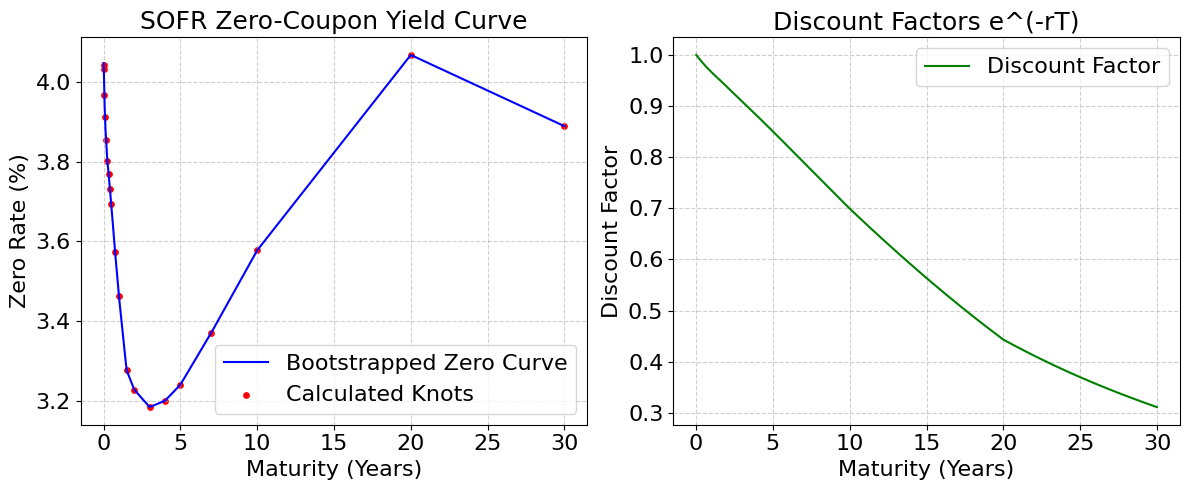

In [5]:
# 1. Generate a time grid from 0 to 30 years
t_grid = np.linspace(0.01, 30, 500)

# 2. Calculate values using your functions
# Note: rate_curve_func returns decimals (0.04), we multiply by 100 for %
zero_rates = rate_curve_func(t_grid) * 100
dfs = DF(t_grid)

# 3. Plotting
plt.figure(figsize=(12, 5))

# Plot 1: Zero Rates
plt.subplot(1, 2, 1)
plt.plot(t_grid, zero_rates, label='Bootstrapped Zero Curve', color='blue')

# Optional: Plot the specific "Known" points calculated by the bootstrapper
# Accessing the internal x/y data of the scipy interpolator
plt.scatter(sofr_zero_curve.x, sofr_zero_curve.y * 100, color='red', s=15, label='Calculated Knots')

plt.title('SOFR Zero-Coupon Yield Curve', fontsize=18)
plt.xlabel('Maturity (Years)', fontsize=16)
plt.ylabel('Zero Rate (%)', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)

# Plot 2: Discount Factors
plt.subplot(1, 2, 2)
plt.plot(t_grid, dfs, label='Discount Factor', color='green')
plt.title('Discount Factors e^(-rT)', fontsize=18)
plt.xlabel('Maturity (Years)', fontsize=16)
plt.ylabel('Discount Factor', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)

plt.tight_layout()
plt.show()

In [6]:
def get_clean_calibration_data(ticker_symbol, min_volume=1):
    """
    Pulls option chain data from yfinance. Doesn't have access to historical data.
    Saves a copy of the data. You need to download it from the sidebar of the Colab notebook.
    You don't need to run this if you already have the data file. Pass the file to resample_semiannual instead.

    Args:
    ticker_symbol: "SPX" for S&P 500
    min_volume: implements minimum volume filtering

    Returns:
    A tuple of the spot price and the clean pandas data frame

    """
    print(f"Retrieving data for {ticker_symbol}")
    asset = yf.Ticker(ticker_symbol)

    # 1. Get spot price
    try:
        history = asset.history(period="1d")
        if history.empty:
            raise ValueError("No historical data found.")
        S0 = history['Close'].iloc[-1]
        print(f"Spot Price (S0): {S0:.2f}")
    except Exception as e:
        print(f"Error getting S0: {e}")
        return None, None

    # 2. Get expirations
    try:
        expirations = asset.options
    except:
        return None, None

    today = datetime.now()
    selected_dates = []

    # Filter dates
    for exp in expirations:
        exp_dt = datetime.strptime(exp, "%Y-%m-%d")
        days = (exp_dt - today).days
        if 30 < days < 1500:
            selected_dates.append(exp)

    all_dfs = []
    raw_dfs = [] # Store raw data for Excel

    for exp in selected_dates:
        exp_date = datetime.strptime(exp, "%Y-%m-%d")
        T = (exp_date - today).days / 365.0
        df_r = DF(T)

        # 1. Retrieve data
        try:
            chain = asset.option_chain(exp)
            calls = chain.calls
            puts = chain.puts
        except:
            continue

        calls['mid_price'] = (calls['bid'] + calls['ask']) / 2
        puts['mid_price'] = (puts['bid'] + puts['ask']) / 2

        # 2. Calculate implied dividend (q)
        try:
            closest_strike_idx = (calls['strike'] - S0).abs().argsort()[:1]
            if closest_strike_idx.empty:
                continue

            K_atm = calls.iloc[closest_strike_idx]['strike'].values[0]

            if K_atm not in puts['strike'].values:
                common_strikes = np.intersect1d(calls['strike'].values, puts['strike'].values)
                if len(common_strikes) == 0:
                    continue
                K_atm = common_strikes[np.abs(common_strikes - S0).argmin()]

            C_atm = calls[calls['strike'] == K_atm]['mid_price'].values[0]
            P_atm = puts[puts['strike'] == K_atm]['mid_price'].values[0]

            parity_val = (C_atm - P_atm + K_atm * df_r) / S0
            if parity_val <= 0:
                implied_q = 0
            else:
                implied_q = -np.log(parity_val) / T

            df_q = np.exp(-implied_q * T)

        except Exception as e:
            print(f"Skipping exp {exp}: Error calc q ({e})")
            continue

        # 3. Select OTM puts & calls
        puts_otm = puts[
            (puts['strike'] < S0) &
            (puts['strike'] > S0 * 0.45) &
            (puts['volume'] >= min_volume)
        ].copy()
        puts_otm['type'] = 'put'

        calls_otm = calls[
            (calls['strike'] >= S0) &
            (calls['strike'] < S0 * 1.25) &
            (calls['volume'] >= min_volume)
        ].copy()
        calls_otm['type'] = 'call'

        df = pd.concat([puts_otm, calls_otm])
        if df.empty:
            continue

        # 4. Calculate mid price
        df['mid_price'] = (df['bid'] + df['ask']) / 2
        df['T'] = T
        df['q'] = implied_q

        # Save raw snapshot before filtering
        raw_dfs.append(df.copy())

        # 5. Quality checks

        # Check A: Liquidity (with Warning)
        liq_mask = df['bid'] > 0.05
        dropped_liq = df[~liq_mask]
        if not dropped_liq.empty:
             print(f"\nDropped {len(dropped_liq)} rows for T={T:.2f} due to Liquidity check."
                   f" Detected (strike {dropped_liq['strike'].iloc[0]} "
                   f"Mid Price {dropped_liq['mid_price'].iloc[0]:.2f})")
        df = df[liq_mask].copy()

        # Check B: Arbitrage (with Warning)
        S_disc = S0 * df_q
        K_disc = df['strike'] * df_r
        intrinsic_val = np.where(
            df['type'] == 'call',
            np.maximum(0, S_disc - K_disc),
            np.maximum(0, K_disc - S_disc)
        )

        valid_price_mask = df['mid_price'] > (intrinsic_val + 0.01)
        dropped_arb = df[~valid_price_mask]
        if not dropped_arb.empty:
             print(f"\nDropped {len(dropped_arb)} rows for T={T:.2f} due to Arbitrage check."
                   f" Detected (strike {dropped_arb['strike'].iloc[0]} "
                   f"Mid Price {dropped_arb['mid_price'].iloc[0]:.2f})")

        df = df[valid_price_mask].copy()

        if df.empty:
            continue

        # 6. Put-Call Parity
        def convert_to_call(row):
            if row['type'] == 'call':
                return row['mid_price']
            else:
                return row['mid_price'] + S_disc - (row['strike'] * df_r)

        df['market_price_call_equivalent'] = df.apply(convert_to_call, axis=1)

        # 7. Monotonicity Check (with Warning)
        df = df.sort_values('strike').reset_index(drop=True)
        rolling_min_price = df['market_price_call_equivalent'].cummin()
        arbitrage_mask = df['market_price_call_equivalent'] <= (rolling_min_price + 0.10)

        dropped_rows = df[~arbitrage_mask]
        if not dropped_rows.empty:
            print(f"\nDropped {len(dropped_rows)} rows for T={T:.2f} due to monotonicity violation."
                  f"Detected jumps (strike {dropped_rows['strike'].iloc[0]} "
                  f"Price {dropped_rows['market_price_call_equivalent'].iloc[0]:.2f})")

        df = df[arbitrage_mask].copy()

        # 8. Select final columns
        clean_df = df[['strike', 'T', 'market_price_call_equivalent', 'impliedVolatility', 'type', 'mid_price', 'q']]
        clean_df = clean_df.rename(columns={'type': 'type_before_conversion', 'impliedVolatility': 'implied_vol', 'q': 'implied_q'})
        all_dfs.append(clean_df)

    if not all_dfs:
        return S0, pd.DataFrame()

    final_df = pd.concat(all_dfs, ignore_index=True)
    final_df = final_df.sort_values(['T', 'strike']).reset_index(drop=True)

    # --- SAVE TO EXCEL ---
    raw_df = pd.concat(raw_dfs, ignore_index=True) if raw_dfs else pd.DataFrame()
    s0_df = pd.DataFrame([{'S0': S0, 'Ticker': ticker_symbol, 'Date': today}])

    # Clean Timezones for Excel compatibility
    for col in raw_df.columns:
        if pd.api.types.is_datetime64_any_dtype(raw_df[col]):
            if raw_df[col].dt.tz is not None:
                raw_df[col] = raw_df[col].dt.tz_localize(None)

    if pd.api.types.is_datetime64_any_dtype(s0_df['Date']):
         if s0_df['Date'].dt.tz is not None:
             s0_df['Date'] = s0_df['Date'].dt.tz_localize(None)

    # Dynamic Filename: calibration_data_December_03_2025.xlsx
    file_date_str = today.strftime("%B_%d_%Y")
    filename = f"calibration_data_{file_date_str}.xlsx"

    try:
        with pd.ExcelWriter(filename) as writer:
            final_df.to_excel(writer, sheet_name="Cleaned Data", index=False)
            raw_df.to_excel(writer, sheet_name="Original Data", index=False)
            s0_df.to_excel(writer, sheet_name="Spot Price", index=False)
        print(f"Data saved to {filename}")
    except Exception as e:
        print(f"Could not save Excel: {e}")

    print(f"Total options retrieved: {len(final_df)}")
    return S0, final_df

In [7]:
# S0, market_data = get_clean_calibration_data("^SPX")

In [8]:
# market_data # Note: yfinance's implied_vol uses different r and q. We keep this data only for a quick check.

In [9]:
def resample_semiannual(input_data, full_schedule=None):
    """
    Filters dataset to match the product's observation structure and liquid market points.
    Can take a file path or a pandas DataFrame. If the input is a file path, you don't need to run
    get_clean_calibration_data, and this funtion will use the S0 value in the Excel file to overwrited S0.

    Args:
        input_data: Either a pandas DataFrame OR a string filename (e.g. "calibration_data_December_03_2025.xlsx").
        full_schedule: List of date strings.
    Returns:
        pandas DataFrame with the selected maturities.
    """
    # Load from file if a string is passed
    if isinstance(input_data, str):
        print(f"Loading data from file: {input_data}")
        if input_data.endswith('.xlsx'):
            # Read the specific sheet where we saved the clean data
            full_df = pd.read_excel(input_data, sheet_name="Cleaned Data")
            global S0
            S0 = pd.read_excel(input_data, sheet_name="Spot Price")['S0'].iloc[0]
            print(f"\nSpot Price (S0): {S0:.2f}. S0 overwritten!")
        else:
            # Fallback for CSVs
            full_df = pd.read_csv(input_data)
    else:
        full_df = input_data.copy()

    available_Ts = np.sort(full_df['T'].unique())
    today = datetime.now()

    # Start with a standard Tenors
    # 1M, 3M, 6M, 1Y, 1.5Y, 2Y, 3Y, 4Y
    targets = [0.08, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]

    # Add product-specific dates
    if full_schedule:
        for d_str in full_schedule:
            d_obj = datetime.strptime(d_str, "%Y-%m-%d")
            if d_obj > today:
                T_rem = (d_obj - today).days / 365.0
                targets.append(T_rem)

    # Sort and Remove Duplicates
    targets = sorted(list(set(targets)))

    print(f"\nCalibration targets: {[f'{t:.2f}' for t in targets]}")

    selected_Ts = []

    # Match market expirations to targets
    for target in targets:
        # Find the available T index that is closest to the target
        closest_idx = (np.abs(available_Ts - target)).argmin()
        closest_T = available_Ts[closest_idx]

        # Avoid selecting the same maturity twice
        if closest_T not in selected_Ts:
            selected_Ts.append(closest_T)
            # Optional: Log if the market data is far from the target
            if abs(closest_T - target) > 0.1:
                 print(f"  > Target {target:.2f}y -> Using {closest_T:.2f}y")

    selected_Ts = np.sort(np.array(selected_Ts))

    # Filter the dataframe
    subset_df = full_df[full_df['T'].isin(selected_Ts)].copy().reset_index(drop=True)

    print(f"\nFinal selection: {len(selected_Ts)} maturities, {len(subset_df)} rows.")

    return subset_df

In [10]:
# Force the dataset to be balanced (e.g., 200 rows for year 4 and 200 rows for year 0.2)
df_calib = resample_semiannual("calibration_data_December_03_2025.xlsx", PRODUCT_SCHEDULE) #market_data
print(df_calib.groupby('T').size())
df_calib

Loading data from file: calibration_data_December_03_2025.xlsx

Spot Price (S0): 6829.37. S0 overwritten!

Calibration targets: ['0.08', '0.25', '0.50', '1.00', '1.50', '1.50', '2.00', '2.00', '2.50', '3.00', '3.01', '3.51', '4.00', '4.01']

Final selection: 8 maturities, 906 rows.
T
0.087671     59
0.232877    308
0.482192     50
0.961644    143
1.534247    154
2.035616     92
3.032877     52
4.049315     48
dtype: int64


,strike,T,market_price_call_equivalent,implied_vol,type_before_conversion,mid_price,implied_q
0,3400,0.087671,3456.093051,0.722659,put,0.225,-0.024806
1,5000,0.087671,1863.265680,0.424109,put,1.925,-0.024806
2,5400,0.087671,1465.958838,0.353247,put,3.250,-0.024806
3,5600,0.087671,1267.642916,0.316810,put,4.250,-0.024806
4,5700,0.087671,1168.634956,0.299171,put,4.900,-0.024806
...,...,...,...,...,...,...,...
901,7200,4.049315,1249.050000,0.259039,call,1249.050,0.001517
902,7400,4.049315,1141.250000,0.252057,call,1141.250,0.001517
903,7600,4.049315,1037.500000,0.245191,call,1037.500,0.001517
904,7800,4.049315,806.850000,0.215461,call,806.850,0.001517


**dividend_curve_func**: Returns interpolated implied dividend yield $q$ for time T

In [11]:
# Extract sorted arrays for T and q from your existing final_df
q_data = df_calib[['T', 'implied_q']].groupby('T').mean().sort_index()
known_ts_q = q_data.index.values
known_qs = q_data['implied_q'].values

# Define the lookup function using np.interp
def dividend_curve_func(T):
    """Returns interpolated implied dividend yield q for time T."""
    # np.interp(target_x, known_x, known_y)
    return np.interp(T, known_ts_q, known_qs)

## 3. Methodology

### Heston Model Dynamics
We model the spot process $S_t$ using the Heston (1993) framework with **Full Truncation** (Lord et al., 2006) for simulation stability.
* **Drift:** Risk-neutral rate $r$ minus dividend yield $q$.
* **Variance:** CIR process with mean reversion $\kappa$, long-run variance $\theta$, and vol-of-vol $\sigma$.
* **Correlation:** Brownian motions correlated by $\rho$.

### Calibration Strategy
Parameters $\Theta = \{\kappa, \theta, \sigma, \rho, v_0\}$ are calibrated to SPX option chains.
* **Pricing Engine:** Lewis (2001) FFT form with rectangular integration.
    * *Constraint:* Uses complex shift $0.5i$ for square-integrability.
    * *Grid:* $N=4096, B=300$ (Satisfies Nyquist constraint).
* **Optimization:** Hybrid approach minimizing Price RMSE.
    1.  **Global:** Differential Evolution (scans parameter space).
    2.  **Local:** L-BFGS-B (refines convexity).

In [12]:
# 1. Initialize
calibrator = HestonFFTCalibrator(df_calib, S0, rate_curve_func)

# 2. Run Calibration
result = calibrator.calibrate()
# params_dec_1 = [2.5028, 0.0546, 1.2363, -0.7101, 0.0306]
# result = calibrator.calibrate(fixed_params=params_dec_1)

print("\nCalibrated parameters")
print(f"Kappa: {result.x[0]:.4f}")
print(f"Theta: {result.x[1]:.4f}")
print(f"Sigma: {result.x[2]:.4f}")
print(f"Rho:   {result.x[3]:.4f}")
print(f"V0:    {result.x[4]:.4f}")

Starting global optimization (Differential Evolution).


/usr/local/lib/python3.12/dist-packages/scipy/optimize/_differentialevolution.py:487: UserWarning: differential_evolution: the 'workers' keyword has overridden updating='immediate' to updating='deferred'
  with DifferentialEvolutionSolver(func, bounds, args=args,


Global Best: [ 2.4095125   0.05480424  1.19469089 -0.72262629  0.03104871], RMSE: 13.2876
Starting Local Optimization (L-BFGS-B).
Local Best: [ 2.4095125   0.05480424  1.19469089 -0.72262629  0.03104871], RMSE: 13.2876

Calibrated parameters
Kappa: 2.4095
Theta: 0.0548
Sigma: 1.1947
Rho:   -0.7226
V0:    0.0310


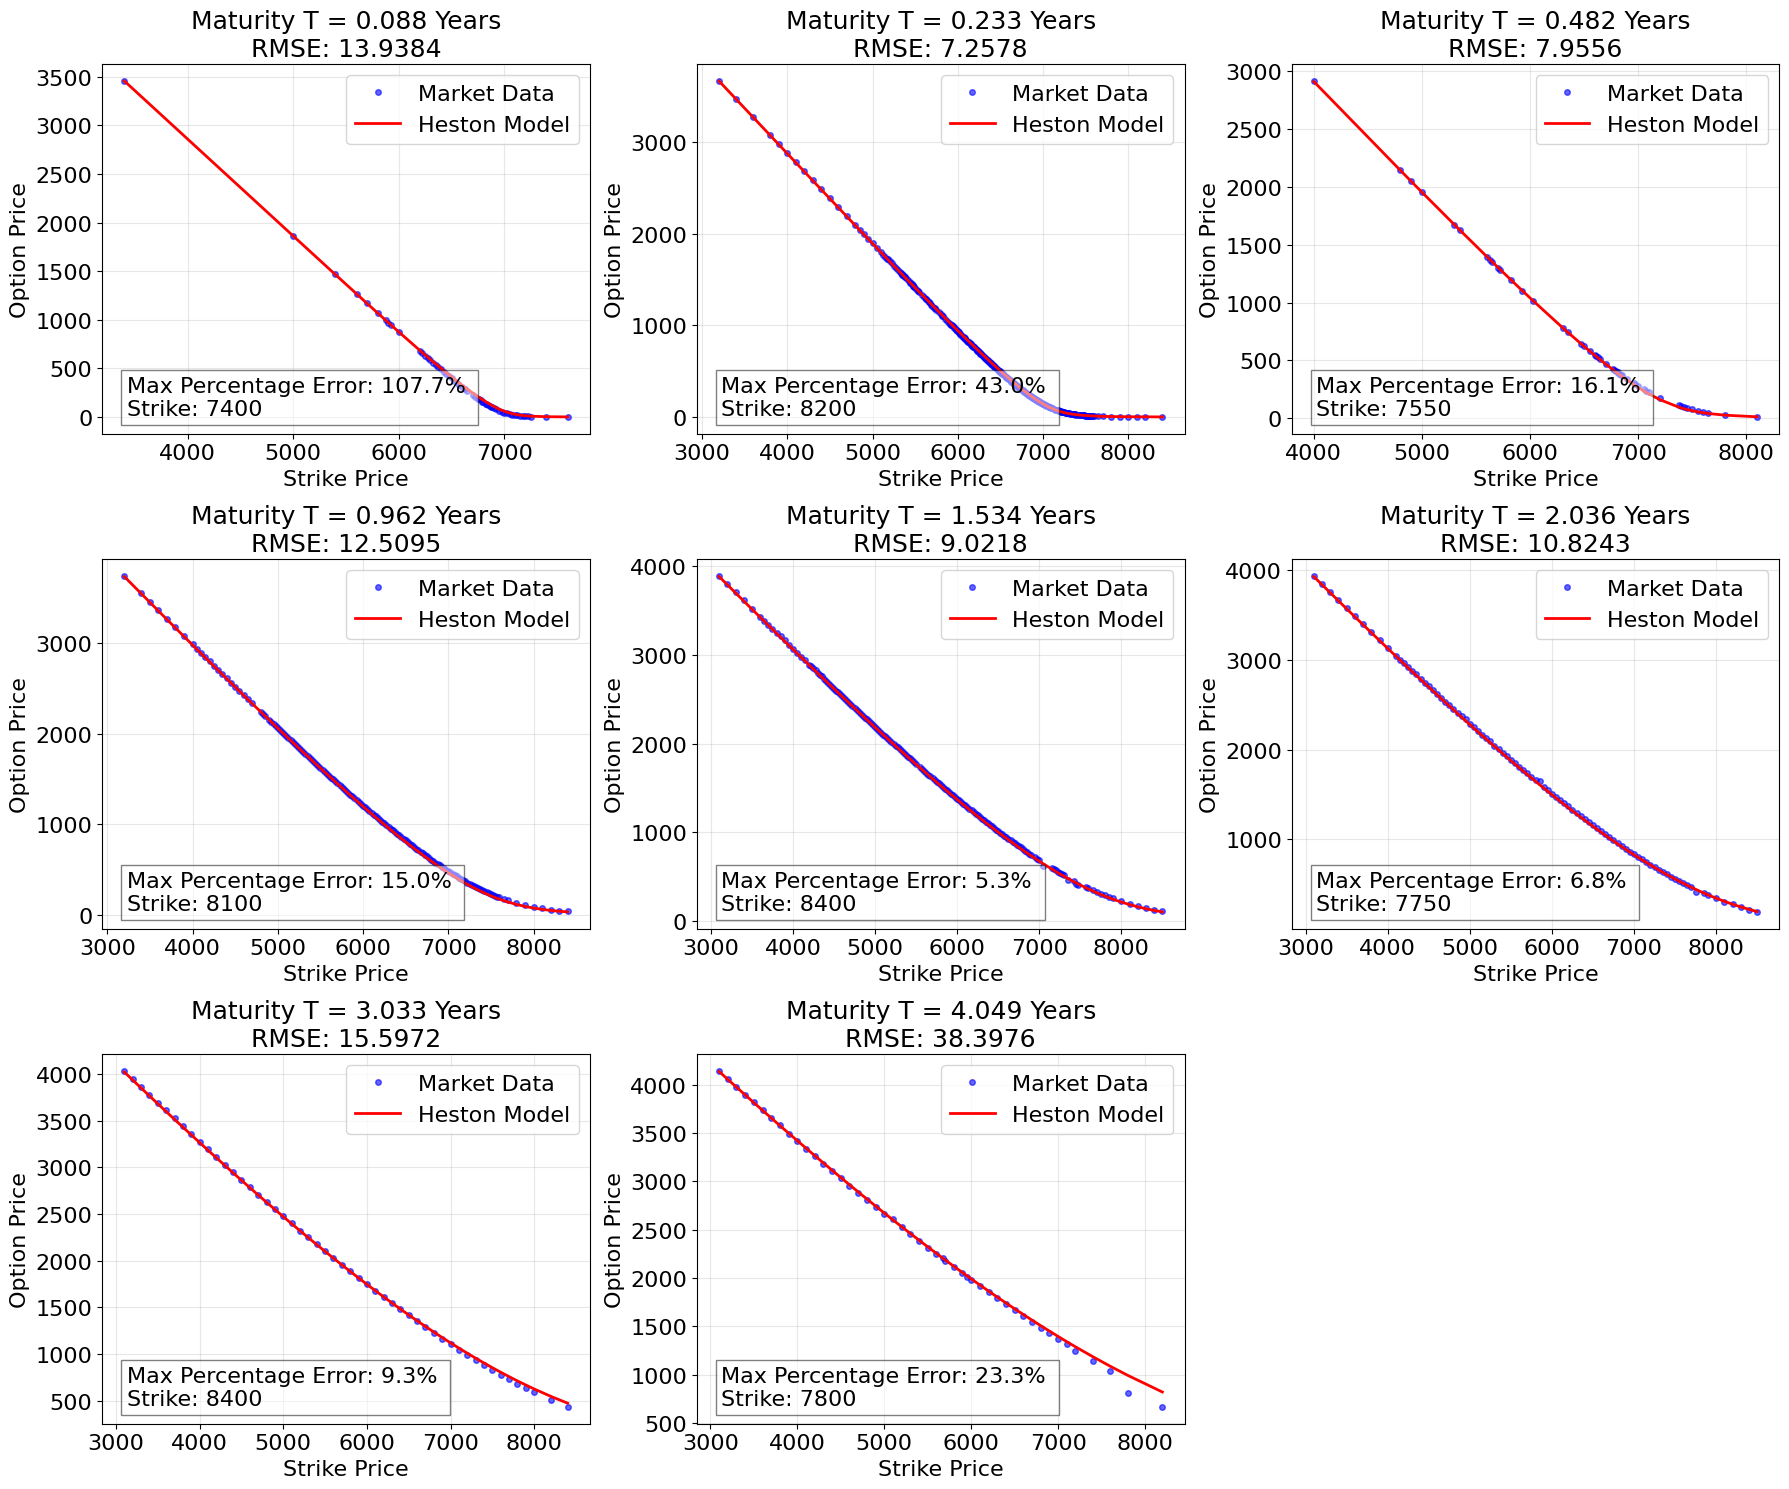

In [13]:
def plot_calibration_results(calibrator, optimal_params):
    """
    Plots Market vs. Heston Model prices for each maturity in the calibrator.

    Args:
        calibrator: The HestonFFTCalibrator instance.
        optimal_params: The calibrated parameters [kappa, theta, sigma, rho, v0].
    """
    # Generate all model prices using the optimal parameters
    all_model_prices = calibrator.price_surface(optimal_params)

    unique_Ts = [b['T'] for b in calibrator.data_batches]
    n_plots = len(unique_Ts)
    cols = 3
    rows = (n_plots + cols - 1) // cols  # Ceiling division

    fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
    axes = axes.flatten()

    current_idx = 0

    for i, batch in enumerate(calibrator.data_batches):
        T = batch['T']
        strikes = batch['strikes']
        market_prices = batch['market_prices']
        n_points = len(strikes)

        # Slice the correct subset of model prices for this maturity
        model_subset = all_model_prices[current_idx : current_idx + n_points]
        current_idx += n_points

        # Calculate local RMSE for this maturity
        rmse = np.sqrt(np.mean((model_subset - market_prices)**2))

        ax = axes[i]
        ax.plot(strikes, market_prices, 'bo', label='Market Data', alpha=0.6, markersize=4)
        ax.plot(strikes, model_subset, 'r-', label='Heston Model', linewidth=2)
        pct_error = (model_subset - market_prices) / (market_prices + 1e-5) * 100 # Avoid division by zero for deep OTM
        max_err = np.max(np.abs(pct_error)) # Add a text annotation for max error
        ax.text(0.05, 0.05, f"Max Percentage Error: {max_err:.1f}% \nStrike: {round(strikes[np.argmax(np.abs(pct_error))])}", transform=ax.transAxes,
                fontsize=16, bbox=dict(facecolor='white', alpha=0.5))

        ax.set_title(f"Maturity T = {T:.3f} Years\nRMSE: {rmse:.4f}", fontsize=18)
        ax.set_xlabel("Strike Price", fontsize=16)
        ax.set_ylabel("Option Price", fontsize=16)
        ax.tick_params(axis='both', which='major', labelsize=16)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=16)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


plot_calibration_results(calibrator, result.x)

In [14]:
def analyze_calibration_results(result):
    kappa, theta, sigma, rho, v0 = result.x

    print("\nHeston Calibration Diagnosis")
    print(f"Calibrated parameters: kappa={kappa:.4f}, theta={theta:.4f}, sigma={sigma:.4f}, rho={rho:.4f}, v0={v0:.4f}")
    print(f"RMSE: {result.fun:.4f}\n")

    print(f"Mean reversion, kappa:  {kappa:.4f}")
    print(f"Long-Term volatility, sqrt(theta):  {np.sqrt(theta):.2%}")
    print(f"Vol-of-Vol, sigma:  {sigma:.4f}")
    print(f"Correlation between Spot and Vol, rho:  {rho:.4f}")
    print(f"Initial volatility, sqrt(v0):  {np.sqrt(v0):.2%}")


    warnings = []

    print("\nFeller condition check")
    # Feller condition check
    lhs = 2 * kappa * theta
    rhs = sigma ** 2

    if lhs > rhs:
        print(f"Feller condition satisfied ({lhs:.4f} > {rhs:.4f})")
    else:
        print(f"Feller condition violated ({lhs:.4f} < {rhs:.4f})")
        print("Variance will hit zero. Use Full Truncation in Monte Carlo.")
        if rhs > 0 and (lhs / rhs) < 0.1:
            warnings.append("Severe Feller violation. Process unstable.")


    # Parameter checks
    print("\n\nParameter checks")
    # Kappa
    if kappa > 10:
        print(f"Kappa is high ({kappa:.2f})")
        warnings.append("High kappa. Fitting short-term noise?")
    elif kappa < 0.5:
        print(f"Kappa is low ({kappa:.2f})")
    else:
        print(f"Kappa is normal ({kappa:.2f})")

    # Sigma
    if sigma > 1.5:
        print(f"Sigma is high ({sigma:.2f})")
        warnings.append("High sigma. High risk of Feller violation instability.")
    elif sigma < 0.01:
        warnings.append("Sigma near zero.")
    else:
        print(f"Sigma is normal ({sigma:.2f})")

    # Rho
    if rho <= -0.99:
        print(f"Rho pinned at lower bound ({rho:.4f})")
        warnings.append("Rho pinned at -1. Check if deep OTM puts are expensive.")
    elif rho >= 0:
        print(f"Rho is positive ({rho:.4f})")
        warnings.append("Positive rho. Unusual for equity.")
    else:
        print(f"Rho is normal ({rho:.2f})")

    # Term structure
    vol_long = np.sqrt(theta)
    vol_curr = np.sqrt(v0)
    if vol_long > vol_curr * 1.5:
        print(f"Upward vol term structure (spot {vol_curr:.1%} -> long {vol_long:.1%})")
    elif vol_curr > vol_long * 1.5:
        print(f"Downward vol term structure (spot {vol_curr:.1%} -> long {vol_long:.1%})")
    else:
        print(f"Flat/stable vol term structure")

    if warnings:
        print("\nWarnings detected:")
        for w in warnings:
            print(f"- {w}")
    else:
        print("\nCalibration looks healthy.")

analyze_calibration_results(result)


Heston Calibration Diagnosis
Calibrated parameters: kappa=2.4095, theta=0.0548, sigma=1.1947, rho=-0.7226, v0=0.0310
RMSE: 13.2876

Mean reversion, kappa:  2.4095
Long-Term volatility, sqrt(theta):  23.41%
Vol-of-Vol, sigma:  1.1947
Correlation between Spot and Vol, rho:  -0.7226
Initial volatility, sqrt(v0):  17.62%

Feller condition check
Feller condition violated (0.2641 < 1.4273)
Variance will hit zero. Use Full Truncation in Monte Carlo.


Parameter checks
Kappa is normal (2.41)
Sigma is normal (1.19)
Rho is normal (-0.72)
Flat/stable vol term structure

Calibration looks healthy.


In [15]:
# # Input Parameters
S_REF = S0 # pricing using today's price as reference

# Unpack Heston parameters: kappa, theta, sigma, rho, v0
params = result.x

# Determine simulation horizon
today = datetime.now()
last_date = datetime.strptime(PRODUCT_SCHEDULE[-1], "%Y-%m-%d")
T_max_years = (last_date - today).days / 365

# Initialize pricer with curve function
pricer = HestonAutocallPricer(
    S0=S0,
    S_ref=S_REF,
    r_curve_func=rate_curve_func, # Pass the bootstrapped function
    q_curve_func=dividend_curve_func,
    params=params
)

# Run simulation
pricer.run_simulation(T_max=T_max_years, steps_per_year=252, n_paths=50000)

price, price_principal, price_coupon, price_put = pricer.price_structure(**PRODUCT_PARAMS) # See beginning for PRODUCT_PARAMS

print(f"\nFair Value: ${price:.2f}")
print(f"Percentage: {(price/1000)*100:.2f}%")
print(f"Expected life: {pricer.expected_life:.2f}")

print("\nProduct terms")
print(PRODUCT_PARAMS)



Simulation complete: 50000 paths over 4.01 years (1011 steps).
Autocallable note price: 987.53,         
Principal component: 947.73,         
Coupon component: 73.80,         
Put risk component (short down-and-in put): -33.99

Fair Value: $987.53
Percentage: 98.75%
Expected life: 1.64

Product terms
{'full_schedule': ['2026-12-21', '2027-06-22', '2027-12-22', '2028-06-22', '2028-12-22', '2029-06-23', '2029-12-23'], 'coupon_step': 0.03, 'barrier_redemption': 0.7, 'barrier_knock_in': 0.6, 'exit_bonus': 0.24, 'nominal': 1000}


### European call IV
Market IV vs Heston IV plots (IV from B-S formula). Sanity check for Heston calibration quality.

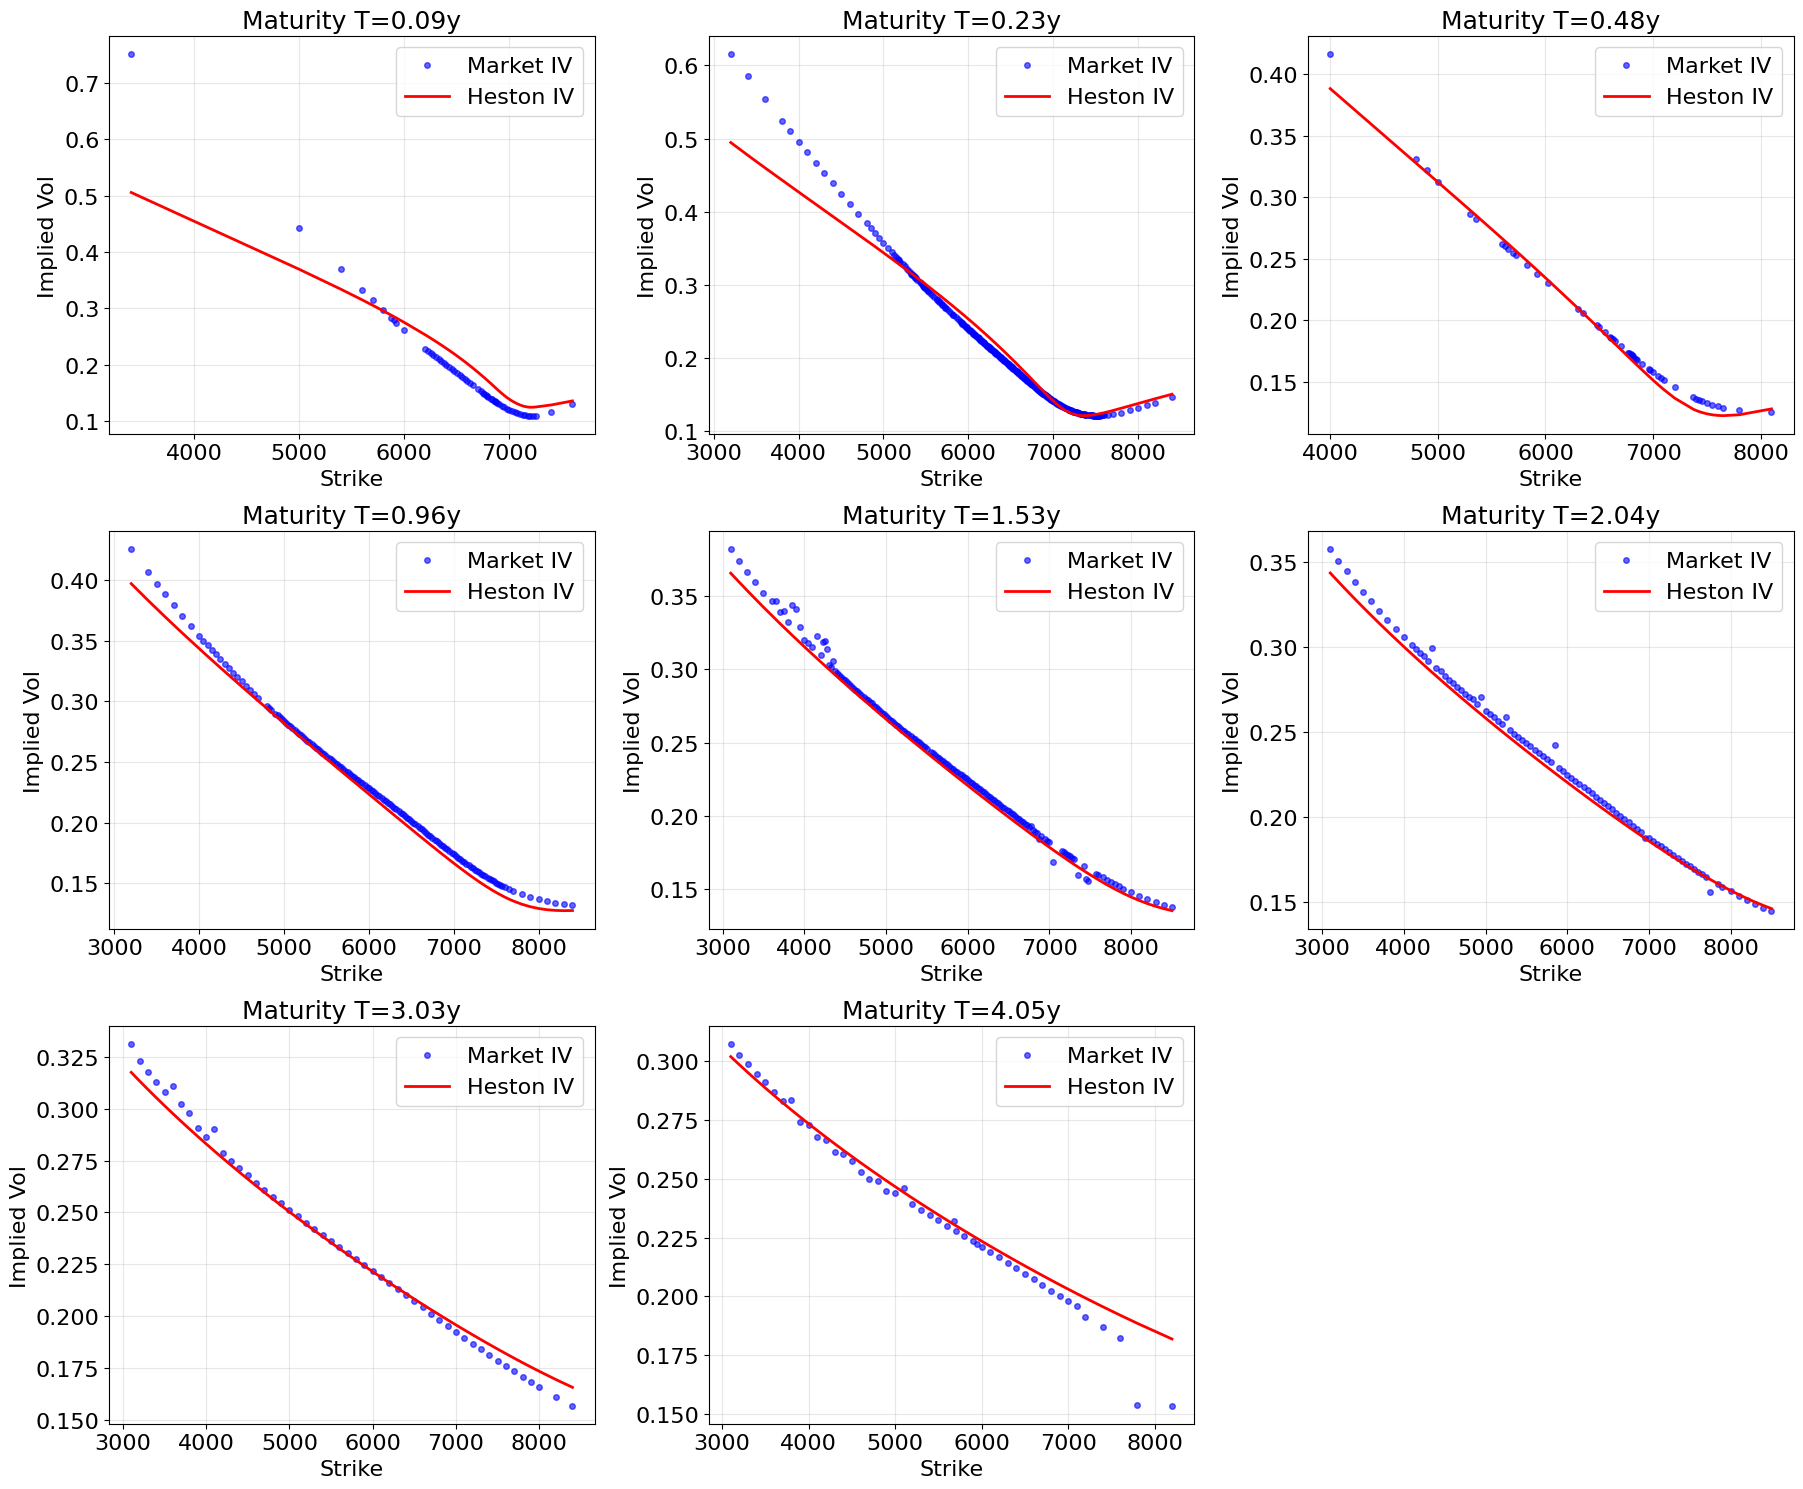

In [16]:
def bs_call(S, K, T, r, q, vol):
    d1 = (np.log(S/K) + (r - q + 0.5*vol*vol)*T) / (vol*np.sqrt(T))
    d2 = d1 - vol*np.sqrt(T)
    return S*np.exp(-q*T)*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

def implied_vol_call(C, S, K, T, r, q):
    # Safety: intrinsic value check
    intrinsic = max(S*np.exp(-q*T) - K*np.exp(-r*T), 0)
    if C <= intrinsic + 1e-5: # Add tiny buffer
        return np.nan
    try:
        # Solving BS(vol) - Price = 0
        return brentq(lambda vol: bs_call(S, K, T, r, q, vol) - C, 1e-6, 5.0)
    except:
        return np.nan

def plot_calibration_iv_smiles(calibrator, optimal_params):
    """
    Plots Market IV vs Heston IV using the calibrator instance.
    """
    # Get Heston model prices using the optimized params
    all_model_prices = calibrator.price_surface(optimal_params)

    # Iterate through batches to plot per maturity
    current_idx = 0

    # Setup subplot grid
    unique_Ts = [b['T'] for b in calibrator.data_batches]
    n_plots = len(unique_Ts)
    cols = 3
    rows = (n_plots + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
    axes = axes.flatten()

    for i, batch in enumerate(calibrator.data_batches):
        T = batch['T']
        strikes = batch['strikes']
        mkt_prices = batch['market_prices']
        qT = batch['q']

        # Get specific rate from your curve function
        rT = calibrator.r_curve(T)

        # Slice model prices corresponding to this batch
        n_points = len(strikes)
        hes_prices = all_model_prices[current_idx : current_idx + n_points]
        current_idx += n_points

        # Calculate IVs using the SAME r and q for both Market and Heston
        mkt_ivs = []
        hes_ivs = []

        for k_i, m_p, h_p in zip(strikes, mkt_prices, hes_prices):
            # Market IV
            mkt_ivs.append(implied_vol_call(m_p, calibrator.S0, k_i, T, rT, qT))
            # Heston IV
            hes_ivs.append(implied_vol_call(h_p, calibrator.S0, k_i, T, rT, qT))

        # Plotting
        ax = axes[i]
        ax.plot(strikes, mkt_ivs, 'bo', label="Market IV", markersize=4, alpha=0.6)
        ax.plot(strikes, hes_ivs, 'r-', label="Heston IV", linewidth=2)

        ax.set_title(f"Maturity T={T:.2f}y", fontsize=18)
        ax.set_xlabel("Strike", fontsize=16)
        ax.set_ylabel("Implied Vol", fontsize=16)
        ax.tick_params(axis='both', which='major', labelsize=16)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=16)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


plot_calibration_iv_smiles(calibrator, result.x)


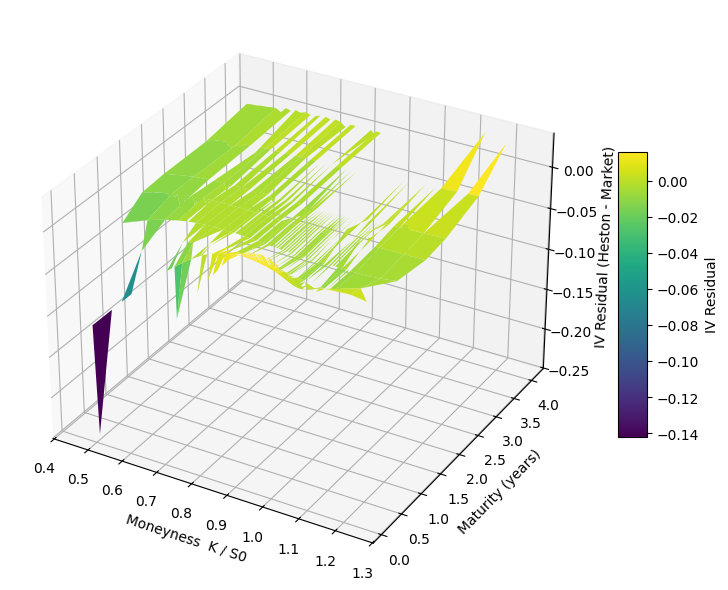

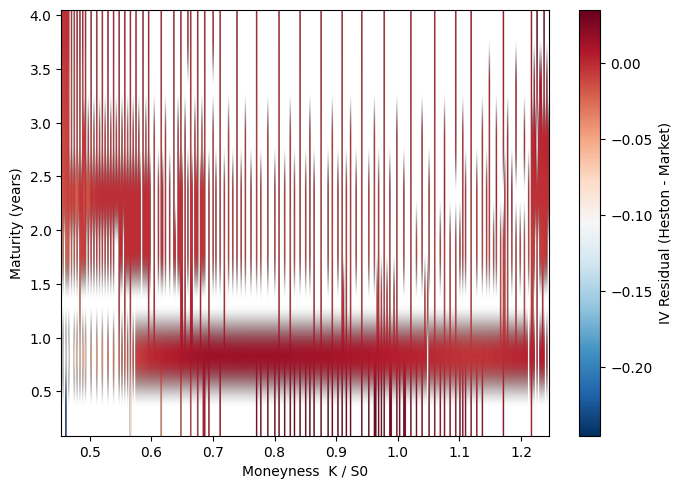

In [17]:
def compute_iv_residual_grid(calibrator, optimal_params):
    """
    Build a rectangular grid of IV residuals (Heston IV - Market IV)
    over (maturity, moneyness) using the existing 'calibrator' object.

    Returns
    -------
    maturity_grid : 1D np.array of maturities (years)
    moneyness_grid: 1D np.array of K / S0
    residuals     : 2D np.array [n_maturities, n_strikes] of IV residuals
                    (may contain np.nan where no data is available)
    """
    # Use existing pricing routine: prices for ALL market points
    all_model_prices = calibrator.price_surface(optimal_params)

    # Collect unique maturities and all unique strikes across batches
    batches = calibrator.data_batches
    unique_T = [b['T'] for b in batches]
    all_strikes = sorted({K for b in batches for K in b['strikes']})

    n_T = len(unique_T)
    n_K = len(all_strikes)

    maturity_grid  = np.array(unique_T)
    moneyness_grid = np.array(all_strikes) / calibrator.S0

    # Residuals matrix: Heston IV - Market IV (NaN where no point exists)
    residuals = np.full((n_T, n_K), np.nan)

    # Pre-build map from strike to column index for speed
    strike_to_idx = {K: j for j, K in enumerate(all_strikes)}

    current_idx = 0

    for i, batch in enumerate(batches):
        T       = batch['T']
        strikes = batch['strikes']
        mkt_px  = batch['market_prices']
        qT      = batch['q']
        rT      = calibrator.r_curve(T)

        n_points = len(strikes)
        hes_px   = all_model_prices[current_idx : current_idx + n_points]
        current_idx += n_points

        # Convert prices -> IV using existing implied_vol_call()
        mkt_iv = np.array([
            implied_vol_call(C=float(C), S=calibrator.S0, K=float(K), T=T, r=rT, q=qT)
            for C, K in zip(mkt_px, strikes)
        ])
        hes_iv = np.array([
            implied_vol_call(C=float(C), S=calibrator.S0, K=float(K), T=T, r=rT, q=qT)
            for C, K in zip(hes_px, strikes)
        ])

        # Fill residual matrix
        for K, iv_mkt, iv_hes in zip(strikes, mkt_iv, hes_iv):
            j = strike_to_idx[K]
            residuals[i, j] = iv_hes - iv_mkt

    return maturity_grid, moneyness_grid, residuals


def plot_residual_surface_3d(maturity_grid, moneyness_grid, residuals):
    """
    3D surface of IV residuals (Heston IV - Market IV).
    """
    # Build meshgrid
    T_grid, K_grid = np.meshgrid(maturity_grid, moneyness_grid, indexing='ij')
    Z = residuals.copy()

    # Mask NaNs if any
    Z_masked = np.ma.masked_invalid(Z)

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')

    surf = ax.plot_surface(
        K_grid,          # x-axis: moneyness (K/S0)
        T_grid,          # y-axis: maturity
        Z_masked,        # z-axis: residual
        cmap='viridis',
        edgecolor='none'
    )

    ax.set_xlabel('Moneyness  K / S0')
    ax.set_ylabel('Maturity (years)')
    ax.set_zlabel('IV Residual (Heston - Market)')
    fig.colorbar(surf, shrink=0.5, aspect=10, label='IV Residual')

    plt.tight_layout()
    plt.savefig('iv_residual_surface_3d.png', dpi=300, bbox_inches='tight')
    plt.show()


def plot_residual_heatmap(maturity_grid, moneyness_grid, residuals):
    """
    Heatmap of IV residuals (Heston IV - Market IV).
    """
    fig, ax = plt.subplots(figsize=(7, 5))

    im = ax.imshow(
        residuals,
        origin='lower',
        aspect='auto',
        extent=[
            moneyness_grid[0], moneyness_grid[-1],
            maturity_grid[0], maturity_grid[-1]
        ],
        cmap='RdBu_r'
    )

    ax.set_xlabel('Moneyness  K / S0')
    ax.set_ylabel('Maturity (years)')
    cbar = fig.colorbar(im)
    cbar.set_label('IV Residual (Heston - Market)')

    plt.tight_layout()
    plt.savefig('iv_residual_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()


# Use existing 'calibrator' and 'result' objects
opt_params = result.x  # [kappa, theta, sigma, rho, v0]

maturity_grid, moneyness_grid, residuals = compute_iv_residual_grid(
    calibrator, opt_params
)

plot_residual_surface_3d(maturity_grid, moneyness_grid, residuals)
plot_residual_heatmap(maturity_grid, moneyness_grid, residuals)


### European call Greeks
Sanity check for Heston calibration quality.

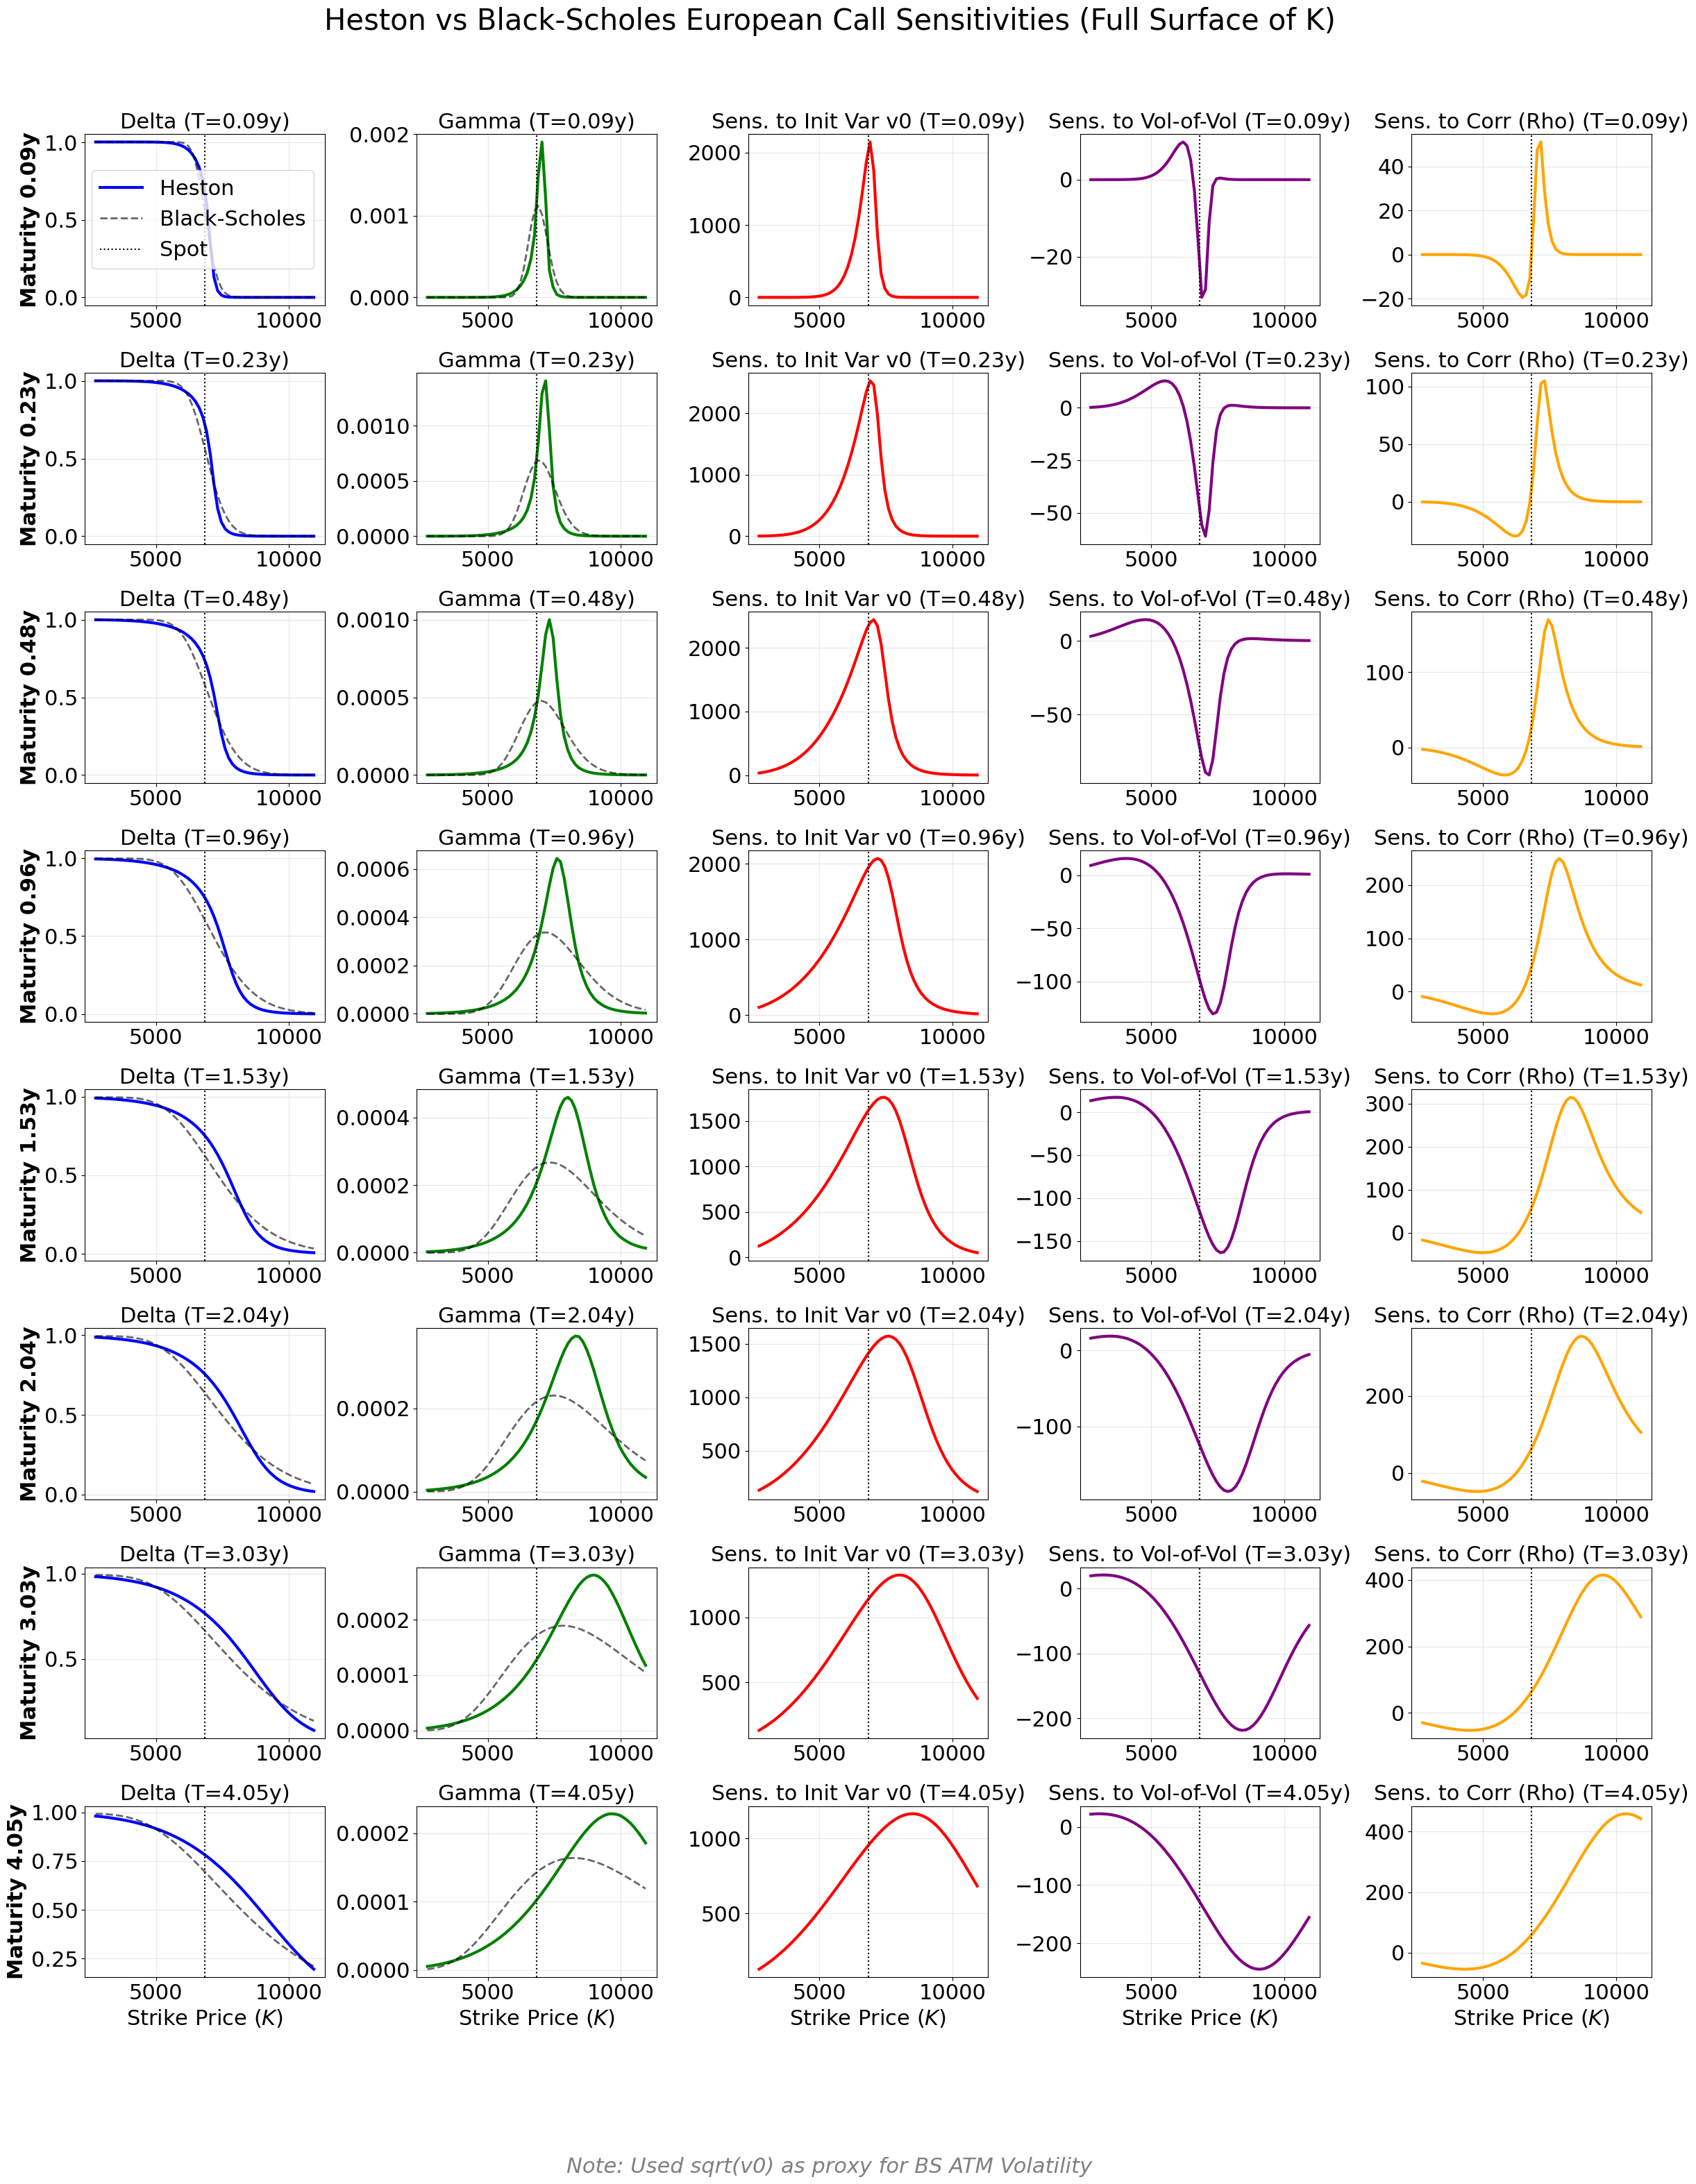

In [18]:
def calculate_bs_call_greeks(S, K, T, r, q, sigma):
    """
    Analytic Black-Scholes Delta and Gamma for Call Options.

    Args:
    S: Current stock price
    K: Strike price
    T: Maturity
    r: Riskfree rate
    q: Dividend rate
    sigma: Volatility

    Returns:
    delta, gamma
    """
    # Prevent division by zero for very short maturities
    T = np.maximum(T, 1e-5)

    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    nd1 = norm.pdf(d1)
    Nd1 = norm.cdf(d1)

    delta = np.exp(-q * T) * Nd1
    gamma = (np.exp(-q * T) * nd1) / (S * sigma * np.sqrt(T))

    return delta, gamma

def calculate_heston_call_greeks(calibrator, params):
    """
    Calculates Heston Delta, Gamma, Vega (v0), and Volga (sigma) for ALL market options
    using the FFT engine (vectorized).

    Args:
    calibrator: HestonCalibration object
    params: Optimized Heston parameters

    Returns:
    delta, gamma, sensitivity to initial variance v0 (vega), sensitivity to vol-and-vol rho (volga)
    """
    calib = copy.deepcopy(calibrator)
    # Use small epsilon for FFT to capture sharp peaks
    eps_spot = calibrator.S0 * 0.001
    eps_vol  = 1e-4

    # Delta, Gamma
    S0_orig = calib.S0

    calib.S0 = S0_orig + eps_spot
    for b in calib.data_batches:
        b['k_market'] = np.log(calib.S0 / b['strikes'])
    C_up = calib.price_surface(params)

    calib.S0 = S0_orig - eps_spot
    for b in calib.data_batches:
        b['k_market'] = np.log(calib.S0 / b['strikes'])
    C_dn = calib.price_surface(params)

    calib.S0 = S0_orig
    for b in calib.data_batches:
        b['k_market'] = np.log(calib.S0 / b['strikes'])
    C_mid = calib.price_surface(params)

    delta = (C_up - C_dn) / (2 * eps_spot)
    gamma = (C_up - 2 * C_mid + C_dn) / (eps_spot**2)

    # Vega, Volga
    kappa, theta, sigma, rho, v0 = params

    params_v_up = [kappa, theta, sigma, rho, v0 + eps_vol]
    params_v_dn = [kappa, theta, sigma, rho, v0 - eps_vol]
    C_v_up = calib.price_surface(params_v_up)
    C_v_dn = calib.price_surface(params_v_dn)
    vega_v0 = (C_v_up - C_v_dn) / (2 * eps_vol)

    params_s_up = [kappa, theta, sigma + eps_vol, rho, v0]
    params_s_dn = [kappa, theta, sigma - eps_vol, rho, v0]
    C_s_up = calib.price_surface(params_s_up)
    C_s_dn = calib.price_surface(params_s_dn)
    sens_sigma = (C_s_up - C_s_dn) / (2 * eps_vol)

    # Sens to Correlation (Heston Rho)
    params_r_up = [kappa, theta, sigma, rho + eps_vol, v0]
    params_r_dn = [kappa, theta, sigma, rho - eps_vol, v0]
    C_r_up = calib.price_surface(params_r_up)
    C_r_dn = calib.price_surface(params_r_dn)
    sens_rho = (C_r_up - C_r_dn) / (2 * eps_vol)

    return delta, gamma, vega_v0, sens_sigma, sens_rho


def plot_greeks_profile(calibrator, params):
    """
    Plots Greeks vs Strike.
    Overlays BS for Delta/Gamma. Plots Heston-specific sensitivities for others.
    """

    plot_calib = copy.deepcopy(calibrator)
    S0 = plot_calib.S0
    wide_strikes = np.linspace(S0 * 0.4, S0 * 1.6, 60)

    for batch in plot_calib.data_batches:
        batch['strikes'] = wide_strikes
        batch['k_market'] = np.log(S0 / wide_strikes)

    delta, gamma, vega, volga, sens_rho = calculate_heston_call_greeks(plot_calib, params)

    unique_Ts = [b['T'] for b in plot_calib.data_batches]
    n_rows = len(unique_Ts)
    fig, axes = plt.subplots(n_rows, 5, figsize=(24, 4 * n_rows))

    FS_SUP   = 30
    FS_TITLE = 22
    FS_LABEL = 22
    FS_TICK  = 22

    current_idx = 0
    # Use sqrt(v0) as proxy for BS ATM Volatility
    bs_vol_proxy = np.sqrt(params[4])

    for i, T in enumerate(unique_Ts):
        strikes = wide_strikes
        n_points = len(strikes)

        # Get Rates/Divs for BS
        r_t = calibrator.r_curve(T)
        q_t = plot_calib.data_batches[i]['q']

        # Calculate BS Greeks (Delta/Gamma only)
        bs_d, bs_g = calculate_bs_call_greeks(
            S0, strikes, T, r_t, q_t, bs_vol_proxy
        )

        # Slices
        d_sub = delta[current_idx : current_idx + n_points]
        g_sub = gamma[current_idx : current_idx + n_points]
        v_sub = vega[current_idx : current_idx + n_points]
        s_sub = volga[current_idx : current_idx + n_points]
        rho_sub = sens_rho[current_idx : current_idx + n_points]
        current_idx += n_points

        # Helper
        def style_ax(ax, title):
            ax.set_title(title, fontsize=FS_TITLE)
            ax.tick_params(axis='both', which='major', labelsize=FS_TICK)
            ax.grid(True, alpha=0.3)
            ax.yaxis.get_offset_text().set_fontsize(FS_TICK)
            ax.axvline(S0, color='k', linestyle=':', alpha=1, label='Spot')

        # Column 0: Delta (overlay BS)
        ax = axes[i, 0] if n_rows > 1 else axes[0]
        ax.plot(strikes, d_sub, 'b-', lw=3, label='Heston')
        ax.plot(strikes, bs_d, 'k--', lw=2, alpha=0.6, label='Black-Scholes')
        style_ax(ax, f"Delta (T={T:.2f}y)")
        ax.set_ylabel(f"Maturity {T:.2f}y", fontsize=FS_LABEL, fontweight='bold')
        if i == 0:
            ax.legend(fontsize=22)

        # Column 1: Gamma (overlay BS)
        ax = axes[i, 1] if n_rows > 1 else axes[1]
        ax.plot(strikes, g_sub, 'g-', lw=3)
        ax.plot(strikes, bs_g, 'k--', lw=2, alpha=0.6)
        style_ax(ax, f"Gamma (T={T:.2f}y)")

        # Column 2: Vega (Heston only)
        ax = axes[i, 2] if n_rows > 1 else axes[2]
        ax.plot(strikes, v_sub, 'r-', lw=3)
        style_ax(ax, f"Sens. to Init Var v0 (T={T:.2f}y)")

        # Column 3: Volga (Heston only)
        ax = axes[i, 3] if n_rows > 1 else axes[3]
        ax.plot(strikes, s_sub, 'purple', lw=3)
        style_ax(ax, f"Sens. to Vol-of-Vol (T={T:.2f}y)")

        # Column 4: Sens to Correlation (Rho, Heston only)
        ax = axes[i, 4] if n_rows > 1 else axes[4]
        ax.plot(strikes, rho_sub, 'orange', lw=3)
        style_ax(ax, f"Sens. to Corr (Rho) (T={T:.2f}y)")

        if i == n_rows - 1:
            for j in range(5):
                axes[i, j].set_xlabel("Strike Price ($K$)", fontsize=FS_LABEL)

    plt.suptitle("Heston vs Black-Scholes European Call Sensitivities (Full Surface of K)", fontsize=FS_SUP, y=0.995)
    fig.text(0.5, 0.02, "Note: Used sqrt(v0) as proxy for BS ATM Volatility",
             ha='center', fontsize=22, style='italic', color='gray')

    plt.tight_layout(rect=[0, 0.08, 1, 0.97], h_pad=2.0)
    plt.show()

plot_greeks_profile(calibrator, result.x)

## 4. Risk Analysis & Interpretation


### Component Greeks (principal + coupons - DI put)
Simulations were performed using 10,000 paths across 60 spot price levels. To optimize performance, the pricing engine was modified to generate "unit paths" ($S_0=1$), allowing specific path sets to be recycled across all spot levels for each sensitivity. An optional time_to_maturity parameter was also implemented to visualize sharp sensitivity changes at shorter maturities.

The note displays clear regime near barriers for coupon and put components, while in the middle for the principal component.

Simulating T=4.01y
Pre-computing paths...
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Scanning 60 spot levels...


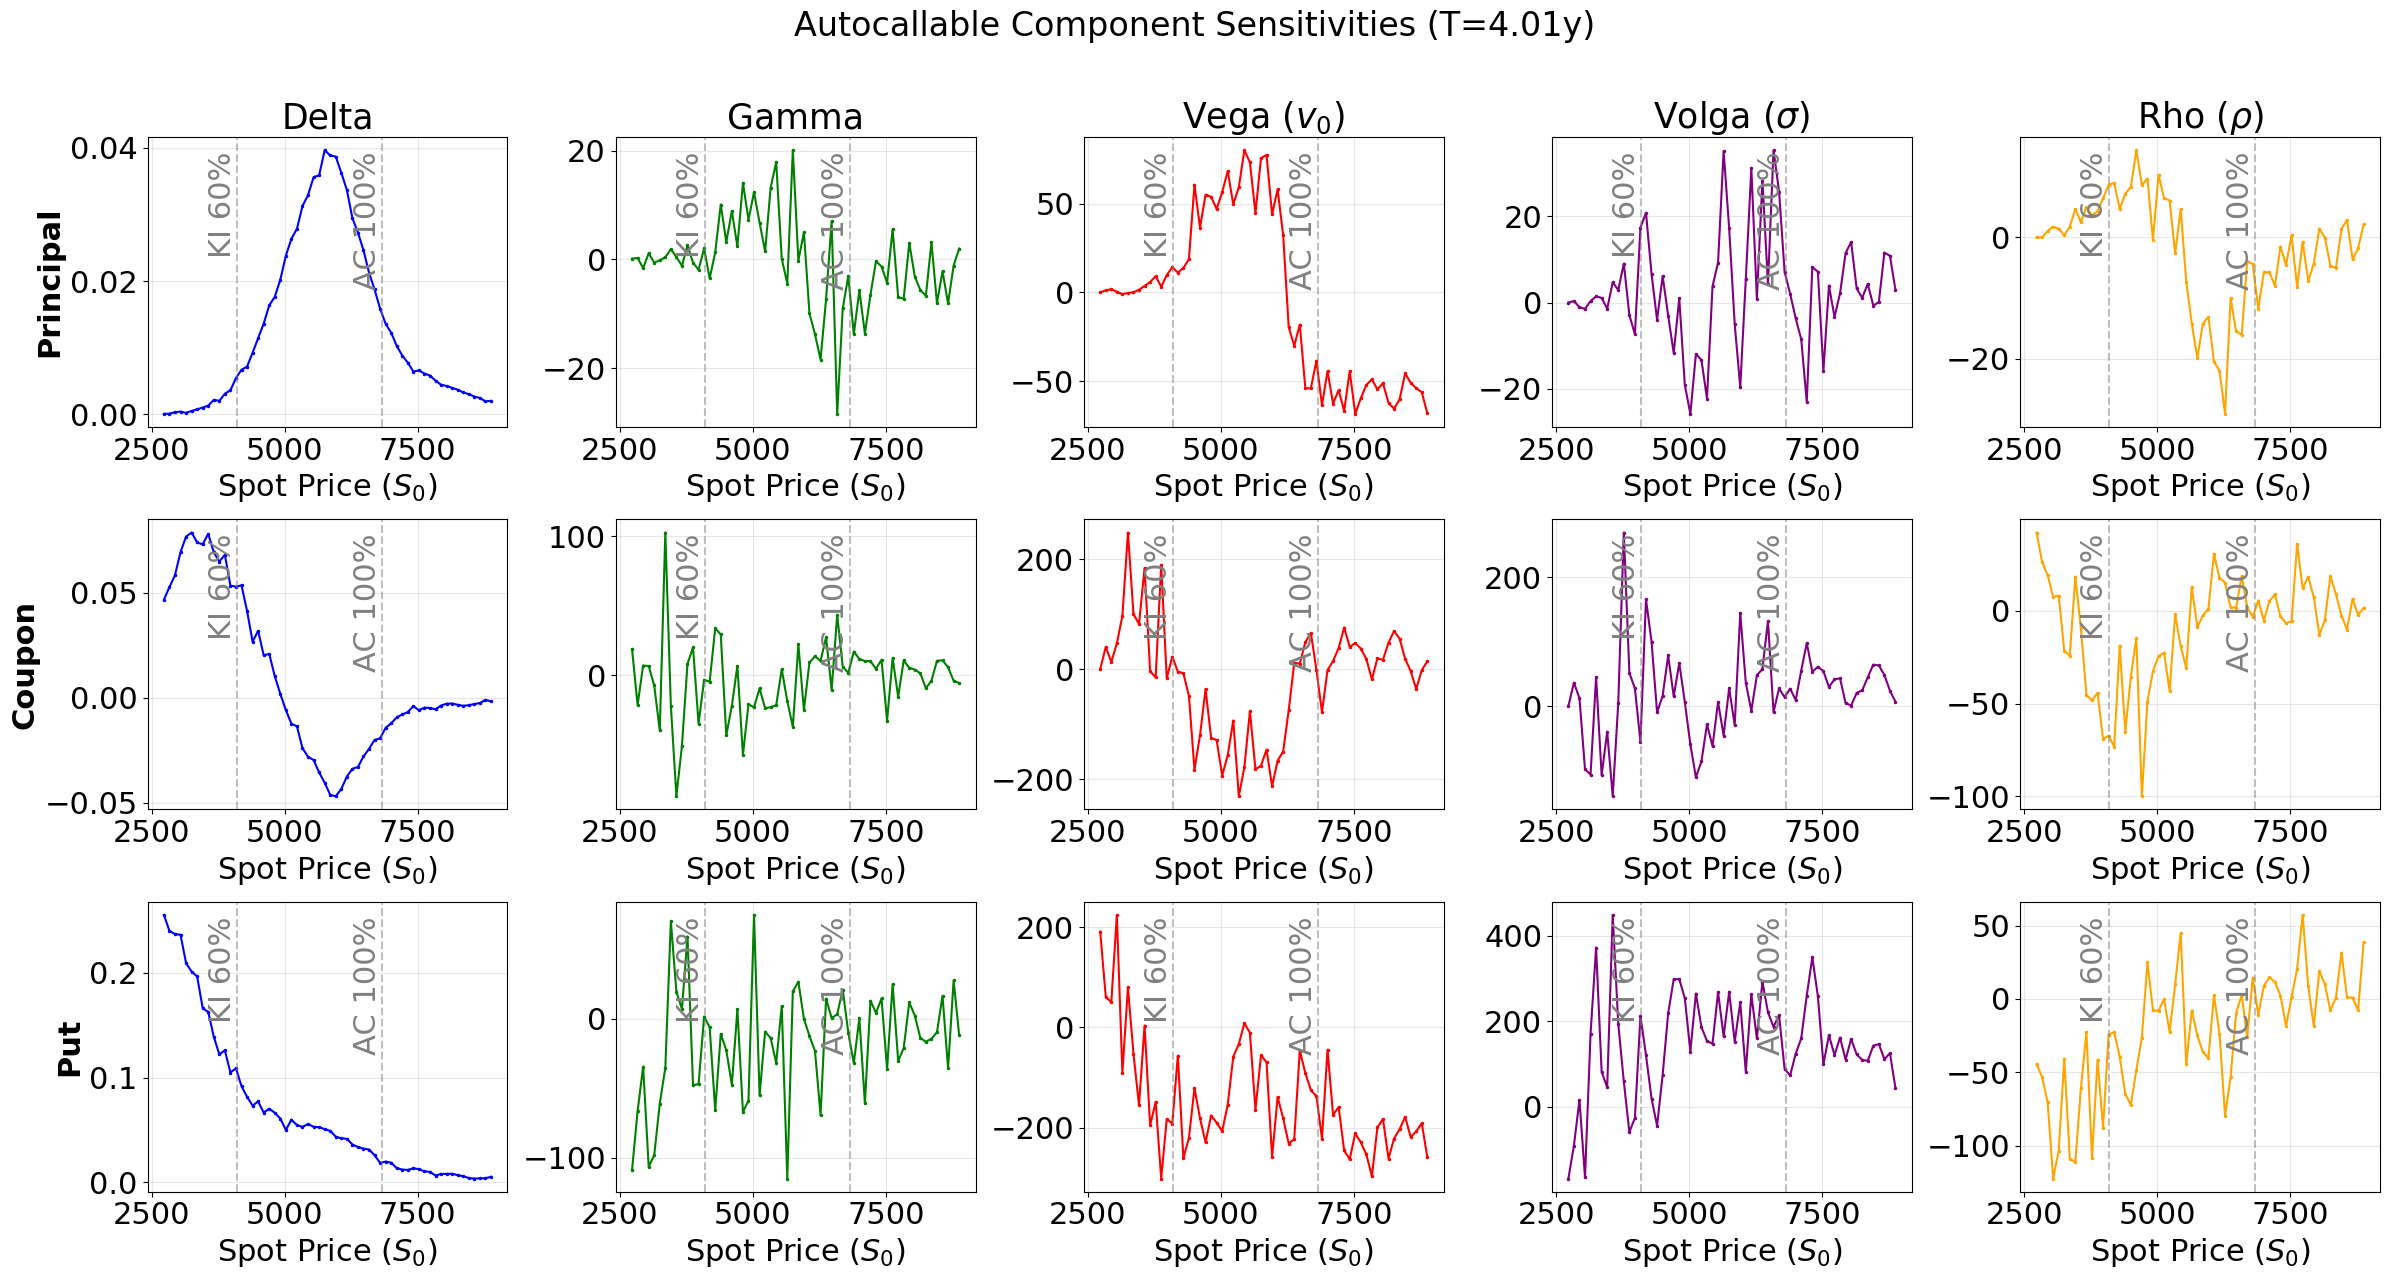

Simulating T=0.4932y (Pricing Date: 2029-06-26)
Pre-computing paths...
Simulation complete: 10000 paths over 0.49 years (125 steps).
Simulation complete: 10000 paths over 0.49 years (125 steps).
Simulation complete: 10000 paths over 0.49 years (125 steps).
Simulation complete: 10000 paths over 0.49 years (125 steps).
Simulation complete: 10000 paths over 0.49 years (125 steps).
Simulation complete: 10000 paths over 0.49 years (125 steps).
Simulation complete: 10000 paths over 0.49 years (125 steps).
Scanning 60 spot levels...


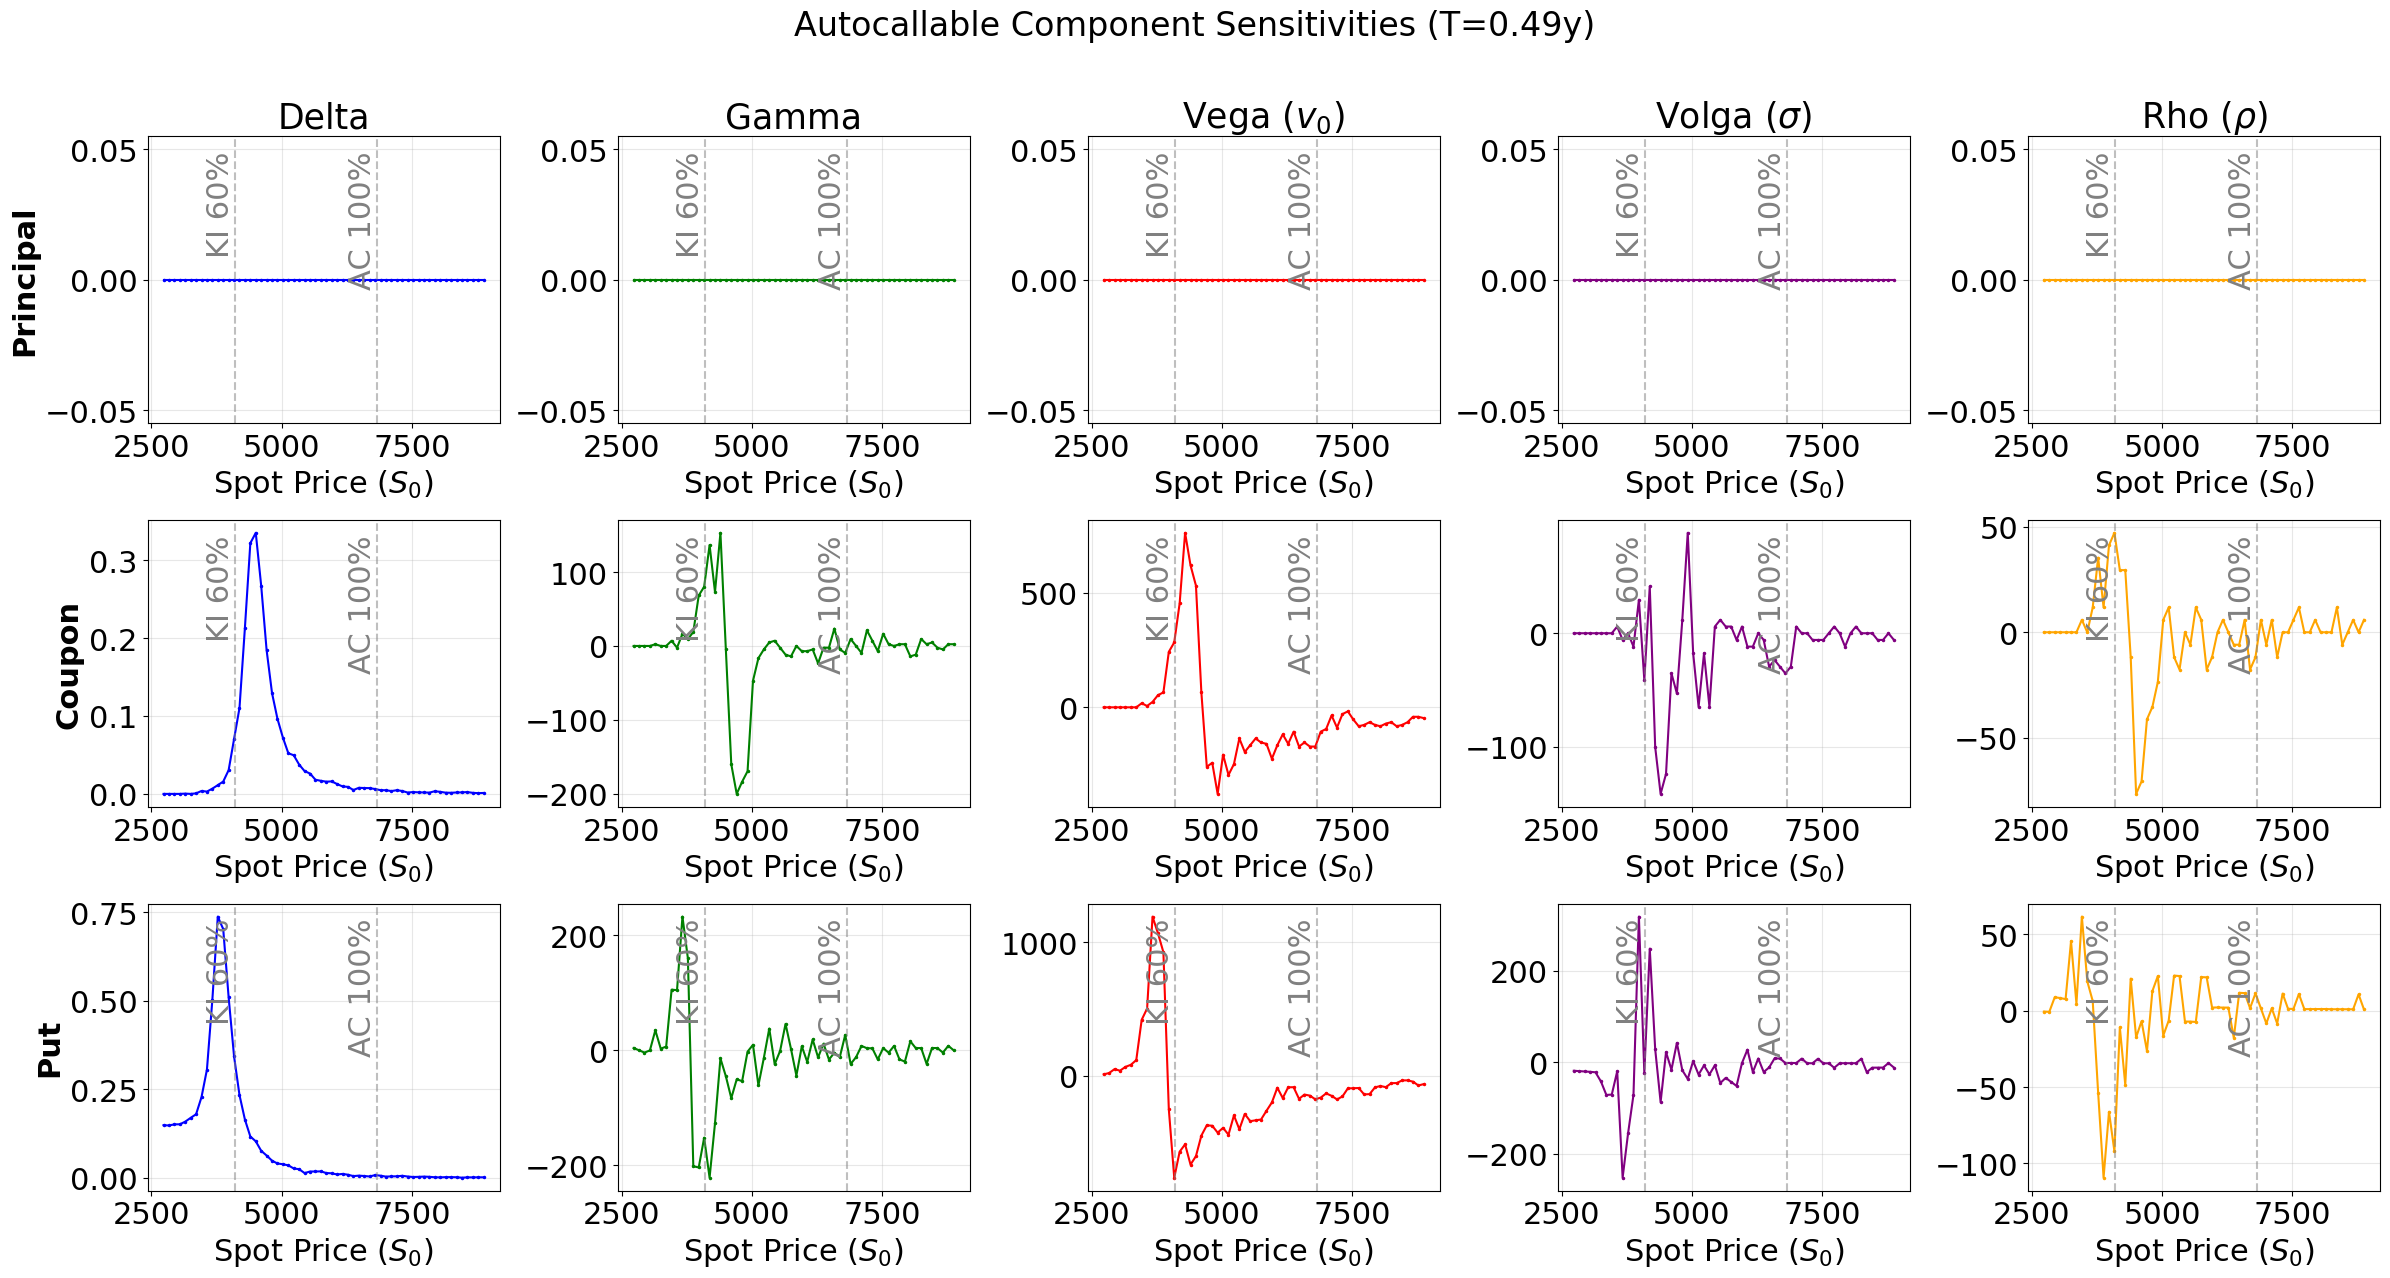

Simulating T=0.0822y (Pricing Date: 2029-11-23)
Pre-computing paths...
Simulation complete: 10000 paths over 0.08 years (21 steps).
Simulation complete: 10000 paths over 0.08 years (21 steps).
Simulation complete: 10000 paths over 0.08 years (21 steps).
Simulation complete: 10000 paths over 0.08 years (21 steps).
Simulation complete: 10000 paths over 0.08 years (21 steps).
Simulation complete: 10000 paths over 0.08 years (21 steps).
Simulation complete: 10000 paths over 0.08 years (21 steps).
Scanning 60 spot levels...


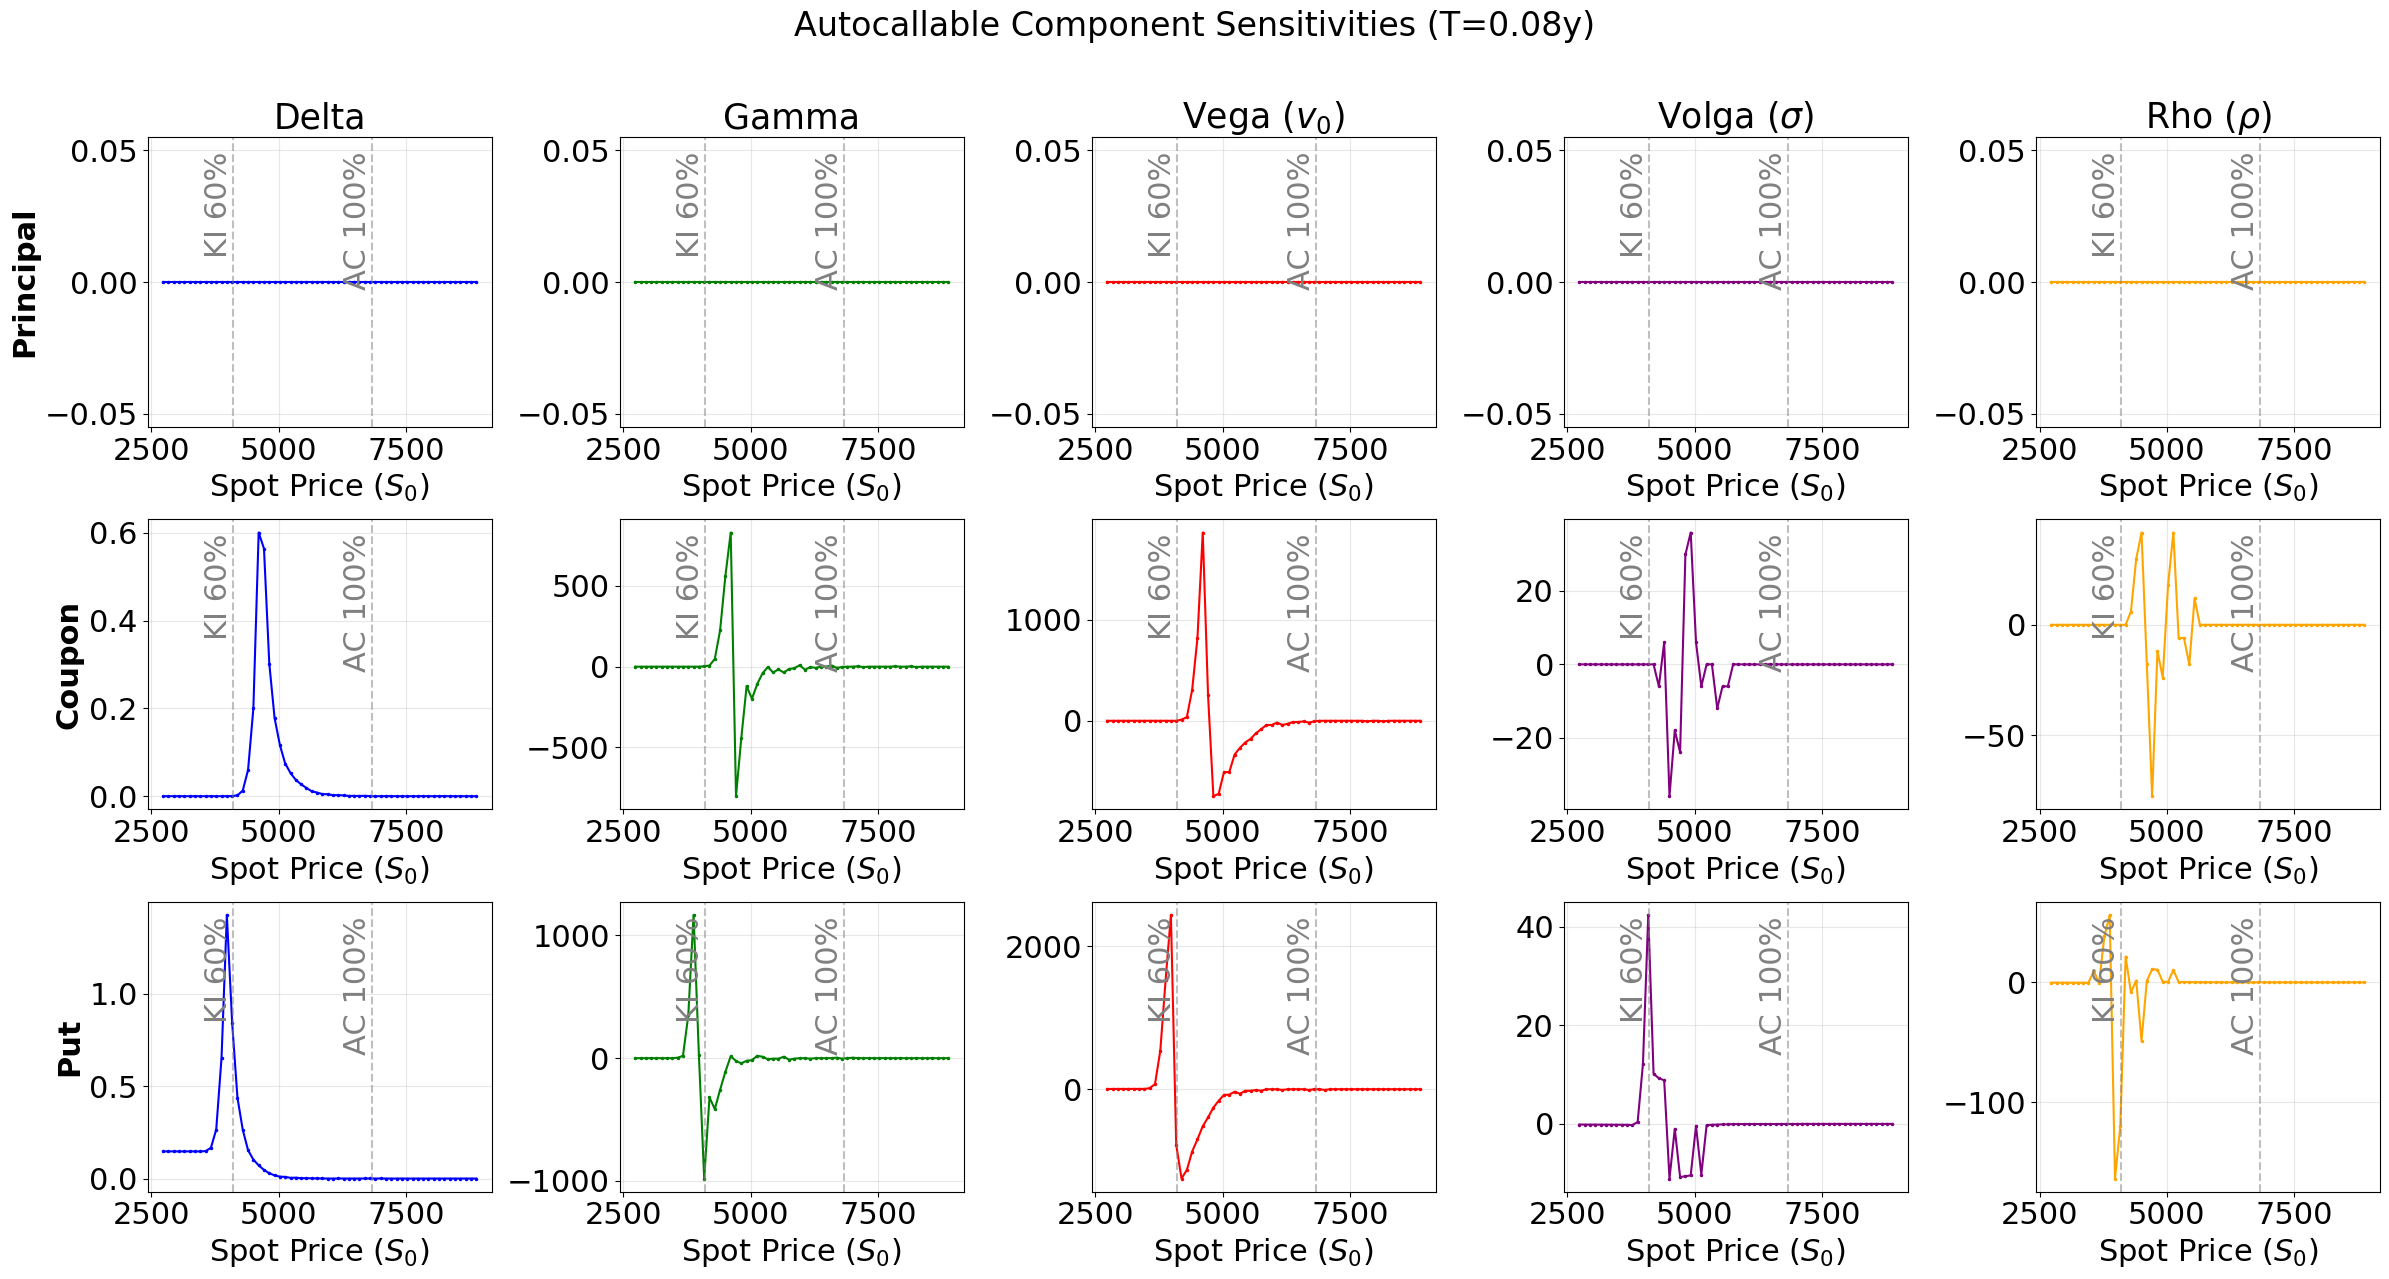

In [19]:
def plot_component_greeks(base_pricer, product_params, time_to_maturity=None):
    s_ref = base_pricer.S_ref
    spots = np.linspace(s_ref * 0.4, s_ref * 1.3, 60)


    last_date_str = product_params['full_schedule'][-1]
    maturity_date = datetime.strptime(last_date_str, "%Y-%m-%d")
    today = datetime.now()
    full_horizon_years = (maturity_date - today).days / 365

    # Deterine time to maturity and pricing date
    if time_to_maturity is not None:
        # Force T to specific value
        T_sim = time_to_maturity

        # Calculate the theoretical future pricing date
        mat_date_str = product_params['full_schedule'][-1]
        mat_date = datetime.strptime(mat_date_str, "%Y-%m-%d")
        sim_date = mat_date - timedelta(days=int(T_sim * 365))

        print(f"Simulating T={T_sim:.4f}y (Pricing Date: {sim_date.date()})")
    else:
        # Standard mode: use pricer's grid or default to 4y
        T_sim = max(full_horizon_years, 0.01)
        sim_date = None
        print(f"Simulating T={T_sim:.2f}y")

    print("Pre-computing paths...")
    greek_paths = base_pricer.generate_greek_paths(T_max=T_sim, n_paths=10000)

    print(f"Scanning {len(spots)} spot levels...")
    history = {'Principal': [], 'Coupon': [], 'Put': []}

    for s in spots:
        temp_p = copy.copy(base_pricer)
        temp_p.S0 = s

        # Explicitly pass the pre-computed data
        with suppress_stdout():
            greeks = temp_p.compute_sensitivities(product_params, path_set=greek_paths, pricing_date=sim_date)

        for c in ['Principal', 'Coupon', 'Put']:
            history[c].append(greeks[c])

    # Plot
    fig, axes = plt.subplots(3, 5, figsize=(24, 13))
    components = ['Principal', 'Coupon', 'Put']
    greeks = ['Delta', 'Gamma', 'Vega', 'Volga', 'Rho']
    colors = ['blue', 'green', 'red', 'purple', 'orange']

    for i, comp in enumerate(components):
        data_list = history[comp]

        for j, greek in enumerate(greeks):
            ax = axes[i, j]
            y_vals = [d[greek] for d in data_list]
            ax.plot(spots, y_vals, '.-', color=colors[j], lw=1.5, markersize=3)
            ax.tick_params(axis='both',which='major', labelsize=22)

            if i == 0:
                title_map = {
                    'Vega': r'Vega ($v_0$)',
                    'Volga': r'Volga ($\sigma$)',
                    'Rho': r'Rho ($\rho$)'
                }
                ax.set_title(title_map.get(greek, greek), fontsize=25)

            if j == 0:
                ax.set_ylabel(comp, fontsize=22, fontweight='bold')

            ax.grid(True, alpha=0.3)

            # Barriers text
            ki_level = s_ref * 0.60
            ac_level = s_ref * 1.00

            ax.axvline(ki_level, color='gray', ls='--', alpha=0.5)
            ax.axvline(ac_level, color='gray', ls='--', alpha=0.5)

            trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
            ax.text(ki_level, 0.95, "KI 60%", transform=trans, ha='right', va='top', fontsize=22, color='gray', rotation=90)
            ax.text(ac_level, 0.95, "AC 100%", transform=trans, ha='right', va='top', fontsize=22, color='gray', rotation=90)
            ax.set_xlabel("Spot Price ($S_0$)", fontsize=22)

    if time_to_maturity:
        title = f" (T={T_sim:.2f}y)"
    else:
        title = f" (T={T_sim:.2f}y)"
    plt.suptitle("Autocallable Component Sensitivities"+title, fontsize=24, y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# Run it
plot_component_greeks(pricer, PRODUCT_PARAMS)
plot_component_greeks(pricer, PRODUCT_PARAMS, time_to_maturity = 180/365)
plot_component_greeks(pricer, PRODUCT_PARAMS, time_to_maturity = 30/365)


Scanning Rho sensitivity...
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Autocallable note price: 990.81,         
Principal component: 950.67,         
Coupon component: 70.75,         
Put risk component (short down-and-in put): -30.62
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Autocallable note price: 990.19,         
Principal component: 950.29,         
Coupon component: 71.13,         
Put risk component (short down-and-in put): -31.23
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Autocallable note price: 990.08,         
Principal component: 949.83,         
Coupon component: 71.52,         
Put risk component (short down-and-in put): -31.27
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Autocallable note price: 990.06,         
Principal component: 949.42,         
Coupon component: 72.01,         
Put risk component (short down-and-in put): -31.37
Simulation complete: 10000 paths over 4.01 years (1011 steps

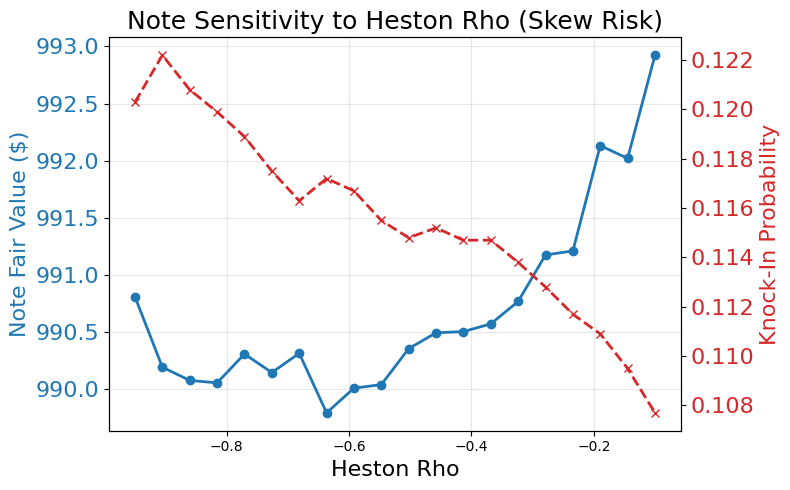

In [20]:
def analyze_product_sensitivities(pricer, product_params, current_params, seed=42):
    """
    Analyzes sensitivity to Rho in Heston model.
    """
    kappa, theta, sigma, rho_orig, v0 = current_params

    # Range of correlations: Heston usually has negative rho (-0.9 to -0.3)
    rho_values = np.linspace(-0.95, -0.1, 20)

    prices = []
    ki_probs = []

    # Barrier Level
    B_knock_in = product_params['barrier_knock_in'] * pricer.S_ref

    print(f"Scanning Rho sensitivity...")

    for rho in rho_values:
        # Update parameters
        new_params = [kappa, theta, sigma, rho, v0]

        # Update pricer
        temp_pricer = HestonAutocallPricer(
            pricer.S0,
            pricer.S_ref,
            pricer.r_curve_func,
            pricer.q_curve_func,
            new_params
        )

        # Determine T_max based on schedule
        last_date = datetime.strptime(product_params['full_schedule'][-1], "%Y-%m-%d")
        current_date = datetime.now()

        T_max = (last_date - current_date).days / 365.0

        np.random.seed(seed)
        temp_pricer.run_simulation(T_max=T_max, steps_per_year=252, n_paths=10000)

        price_tuple = temp_pricer.price_structure(**product_params)
        prices.append(price_tuple[0])

        # Calculate Knock-In Probability
        S_final = temp_pricer.S_paths[-1, :]
        prob = np.mean(S_final < B_knock_in)
        ki_probs.append(prob)

    fig, ax1 = plt.subplots(figsize=(8, 5))

    color = 'tab:blue'
    ax1.set_xlabel('Heston Rho', fontsize=16)
    ax1.set_ylabel('Note Fair Value ($)', color=color, fontsize=16)
    ax1.plot(rho_values, prices, 'o-', color=color, lw=2, label='Note Price')
    ax1.tick_params(axis='y', labelcolor=color, labelsize=16)
    ax1.grid(True, alpha=0.3)

    ax2 = ax1.twinx()
    color = 'tab:red'
    ax2.set_ylabel('Knock-In Probability', color=color, fontsize=16)
    ax2.plot(rho_values, ki_probs, 'x--', color=color, lw=2, label='KI Prob')
    ax2.tick_params(axis='y', labelcolor=color, labelsize=16)

    plt.title("Note Sensitivity to Heston Rho (Skew Risk)", fontsize=18)
    fig.tight_layout()
    plt.show()

analyze_product_sensitivities(pricer, PRODUCT_PARAMS, result.x)

Calculating Price Profile (PV vs Spot)...
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Autocallable note price: 463.38,         
Principal component: 879.57,         
Coupon component: 12.64,         
Put risk component (short down-and-in put): -428.83
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Autocallable note price: 524.30,         
Principal component: 879.59,         
Coupon component: 22.51,         
Put risk component (short down-and-in put): -377.80
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Autocallable note price: 590.60,         
Principal component: 879.62,         
Coupon component: 38.37,         
Put risk component (short down-and-in put): -327.39
Simulation complete: 10000 paths over 4.01 years (1011 steps).
Autocallable note price: 646.28,         
Principal component: 879.78,         
Coupon component: 54.16,         
Put risk component (short down-and-in put): -287.66
Simulation complete: 10000 paths over 4.01

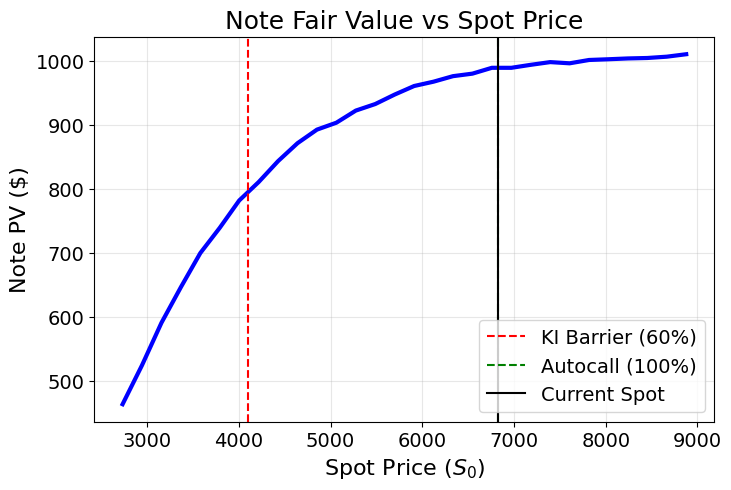

In [21]:
def plot_price_profile(base_pricer, product_params):
    """
    Calculates the Total Note Price vs Spot (The "Payoff Profile").
    """
    S_ref = base_pricer.S_ref

    spot_levels = np.linspace(0.4 * S_ref, 1.3 * S_ref, 30)
    note_prices = []

    print("Calculating Price Profile (PV vs Spot)...")

    # Determine T_max based on schedule in params
    last_date = datetime.strptime(product_params['full_schedule'][-1], "%Y-%m-%d")
    now_date = datetime.now()

    T_max = (last_date - now_date).days / 365

    for S in spot_levels:
        temp_pricer = HestonAutocallPricer(
            S,
            S_ref,
            base_pricer.r_curve_func,
            base_pricer.q_curve_func,
            [base_pricer.kappa, base_pricer.theta, base_pricer.sigma, base_pricer.rho, base_pricer.v0]
        )

        temp_pricer.run_simulation(T_max, steps_per_year=252, n_paths=10000)

        price_tuple = temp_pricer.price_structure(**product_params)
        note_prices.append(price_tuple[0])

    plt.figure(figsize=(8, 5))
    plt.plot(spot_levels, note_prices, 'b-', lw=3)

    plt.axvline(0.60 * S_ref, color='r', linestyle='--', label='KI Barrier (60%)')
    plt.axvline(1.00 * S_ref, color='g', linestyle='--', label='Autocall (100%)')

    plt.axvline(base_pricer.S0, color='black', linestyle='-', label='Current Spot')

    plt.title("Note Fair Value vs Spot Price", fontsize=18)
    plt.xlabel("Spot Price ($S_0$)", fontsize=16)
    plt.ylabel("Note PV ($)", fontsize=16)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.show()

plot_price_profile(pricer, PRODUCT_PARAMS)

References

Heston (1993): "A Closed-Form Solution for Options with Stochastic Volatility."

Lewis (2001): "A Simple Option Formula for General Jump-Diffusion Models."

Code Reference: The FFT calibration implementation was adapted from the Financial Models & Numerical Methods repository by [Cantaro86](https://github.com/cantaro86/Financial-Models-Numerical-Methods).

Simulation complete: 50000 paths over 4.01 years (1011 steps).
MC price with simplified payoff rules: 1022.30


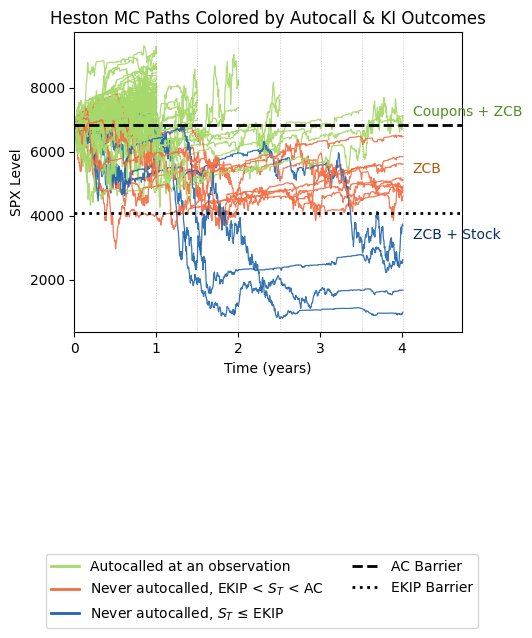

In [22]:

def run_autocall_mc_and_plot(
    pricer,
    PRODUCT_SCHEDULE,
    pricing_date=None,           # datetime or "YYYY-MM-DD"; if None uses datetime.now()
    AC_frac=1.0,
    EKIP_frac=0.6,
    notional=1000.0,
    coupon_step=0.0452,
    steps_per_year=252,
    n_paths=50000,
    n_plot=80,
    seed=123,
    out_png="athena_paths_truncated_legend_below.png",
    force_unit_start=False
):
    """
    Recreates your v2 Monte Carlo payoff classification + truncated-path plot,
    using YOUR pricer's API: pricer.run_simulation(T_max, steps_per_year, n_paths, force_unit_start).
    Fixes the '0.08y' issue by forcing simulation to cover the last observation date.
    """

    # -----------------------------
    # 0) Pricing date
    # -----------------------------
    if pricing_date is None:
        pricing_date = datetime.now()
    elif isinstance(pricing_date, str):
        pricing_date = datetime.strptime(pricing_date, "%Y-%m-%d")

    # -----------------------------
    # 1) Build obs_times from schedule
    # -----------------------------
    schedule_dates = [datetime.strptime(d, "%Y-%m-%d") for d in PRODUCT_SCHEDULE]
    future_dates = sorted([d for d in schedule_dates if d > pricing_date])
    if not future_dates:
        raise ValueError(
            "No future observation dates found in PRODUCT_SCHEDULE relative to pricing_date. "
            "Set pricing_date earlier or update PRODUCT_SCHEDULE."
        )

    obs_times = np.array([(d - pricing_date).days / 365.0 for d in future_dates], dtype=float)
    T_maturity = float(obs_times[-1])

    # -----------------------------
    # 2) Ensure simulation horizon covers maturity (fixes 0.08y)
    # -----------------------------
    need_sim = (getattr(pricer, "S_paths", None) is None) or (getattr(pricer, "time_grid", None) is None)

    if need_sim:
        np.random.seed(seed)
        pricer.run_simulation(T_max=T_maturity, steps_per_year=steps_per_year, n_paths=n_paths, force_unit_start=force_unit_start)
    else:
        # If existing sim is too short, re-simulate
        if pricer.time_grid[-1] < T_maturity - 1e-12:
            np.random.seed(seed)
            pricer.run_simulation(T_max=T_maturity, steps_per_year=steps_per_year, n_paths=n_paths, force_unit_start=force_unit_start)

    # Refresh handles
    S_paths = pricer.S_paths
    time_grid = pricer.time_grid
    n_steps_plus_1, n_paths_actual = S_paths.shape

    # -----------------------------
    # 3) Map obs_times to indices
    # -----------------------------
    obs_idx = [pricer._get_time_index(T) for T in obs_times]
    idx_maturity = pricer._get_time_index(T_maturity)

    # -----------------------------
    # 4) Barriers
    # -----------------------------
    AC_barrier = AC_frac * pricer.S_ref
    EKIP = EKIP_frac * pricer.S_ref

    # -----------------------------
    # 5) Payoff rules & classification
    # -----------------------------
    r_curve_func = pricer.r_curve_func

    payoffs = np.zeros(n_paths_actual)

    # 0 → autocalled
    # 1 → never autocalled, EKIP < ST < AC
    # 2 → never autocalled, ST ≤ EKIP
    regions    = np.zeros(n_paths_actual, dtype=int)
    call_index = np.full(n_paths_actual, -1, dtype=int)
    call_time  = np.full(n_paths_actual, np.nan)

    for p in range(n_paths_actual):
        path = S_paths[:, p]

        coupons_paid = 0.0
        autocalled = False
        t_call = None
        idx_call = -1

        for T_obs, idx_obs in zip(obs_times, obs_idx):
            coupons_paid += coupon_step * notional
            if path[idx_obs] > AC_barrier:
                autocalled = True
                t_call = float(T_obs)
                idx_call = int(idx_obs)
                break

        ST = float(path[idx_maturity])

        if autocalled:
            r_call = float(r_curve_func(t_call))
            df_call = np.exp(-r_call * t_call)

            payoffs[p] = (notional + coupons_paid) * df_call
            regions[p] = 0
            call_index[p] = idx_call
            call_time[p] = t_call
        else:
            r_T = float(r_curve_func(T_maturity))
            df_T = np.exp(-r_T * T_maturity)

            if EKIP < ST < AC_barrier:
                payoffs[p] = notional * df_T
                regions[p] = 1
            else:  # ST ≤ EKIP
                stock_payoff = notional * (ST / pricer.S_ref)
                payoffs[p] = (notional + stock_payoff) * df_T
                regions[p] = 2

    mc_price = float(payoffs.mean())
    print(f"MC price with simplified payoff rules: {mc_price:.2f}")

    # -----------------------------
    # 6) Plot (same as v2)
    # -----------------------------
    rng = np.random.default_rng(seed)
    sample_idx = rng.choice(n_paths_actual, size=min(n_plot, n_paths_actual), replace=False)

    color_map = {
        0: "#a6d96a",  # light green (autocalled)
        1: "#f46d43",  # orange (middle band)
        2: "#2166ac",  # dark blue (knock-in region)
    }

    fig, ax = plt.subplots(figsize=(5, 5))

    for idx in sample_idx:
        region = regions[idx]
        col = color_map[region]

        if region == 0 and call_index[idx] >= 0:
            ci = call_index[idx]
            ax.plot(time_grid[:ci+1], S_paths[:ci+1, idx], lw=0.9, alpha=0.9, color=col)
        else:
            ax.plot(time_grid, S_paths[:, idx], lw=0.9, alpha=0.9, color=col)

    ax.axhline(AC_barrier, color="black", linestyle="--", lw=2)
    ax.axhline(EKIP,       color="black", linestyle=":",  lw=2)

    for T_obs in obs_times:
        ax.axvline(T_obs, color="grey", linestyle=":", lw=0.7, alpha=0.4)

    ax.set_xlabel("Time (years)")
    ax.set_ylabel("SPX Level")
    ax.set_title("Heston MC Paths Colored by Autocall & KI Outcomes")

    x_min, x_max = float(time_grid[0]), float(time_grid[-1])
    ax.set_xlim(x_min, x_max * 1.18)

    y_autocall = AC_barrier + 0.15 * (AC_barrier - EKIP)
    y_mid      = 0.5 * (AC_barrier + EKIP)
    y_ki       = EKIP - 0.25 * (AC_barrier - EKIP)
    x_text     = x_max * 1.03

    ax.text(x_text, y_autocall, "Coupons + ZCB", color="#4d9221", fontsize=10, va="center", ha="left")
    ax.text(x_text, y_mid,      "ZCB",          color="#b35806", fontsize=10, va="center", ha="left")
    ax.text(x_text, y_ki,       "ZCB + Stock",  color="#053061", fontsize=10, va="center", ha="left")

    legend_lines = [
        Line2D([0], [0], color=color_map[0], lw=2, label="Autocalled at an observation"),
        Line2D([0], [0], color=color_map[1], lw=2, label="Never autocalled, EKIP < $S_T$ < AC"),
        Line2D([0], [0], color=color_map[2], lw=2, label="Never autocalled, $S_T$ \u2264 EKIP"),
        Line2D([0], [0], color="black", lw=2, linestyle="--", label="AC Barrier"),
        Line2D([0], [0], color="black", lw=2, linestyle=":",  label="EKIP Barrier"),
    ]

    fig.legend(handles=legend_lines, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)
    fig.subplots_adjust(bottom=0.28)

    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()

    return {
        "mc_price": mc_price,
        "payoffs": payoffs,
        "regions": regions,
        "call_index": call_index,
        "call_time": call_time,
        "obs_times": obs_times,
        "obs_idx": obs_idx,
        "T_maturity": T_maturity,
        "idx_maturity": idx_maturity,
        "out_png": out_png,
    }


# ======================
# Call it in main:
# ======================
results = run_autocall_mc_and_plot(
    pricer=pricer,
    PRODUCT_SCHEDULE=PRODUCT_SCHEDULE,
    pricing_date=None,         # OR set to your valuation date: "2025-12-01"
    steps_per_year=252,
    n_paths=50000,
    n_plot=80,
    seed=123,
    out_png="athena_paths_truncated_legend_below.png",
    force_unit_start=False
)


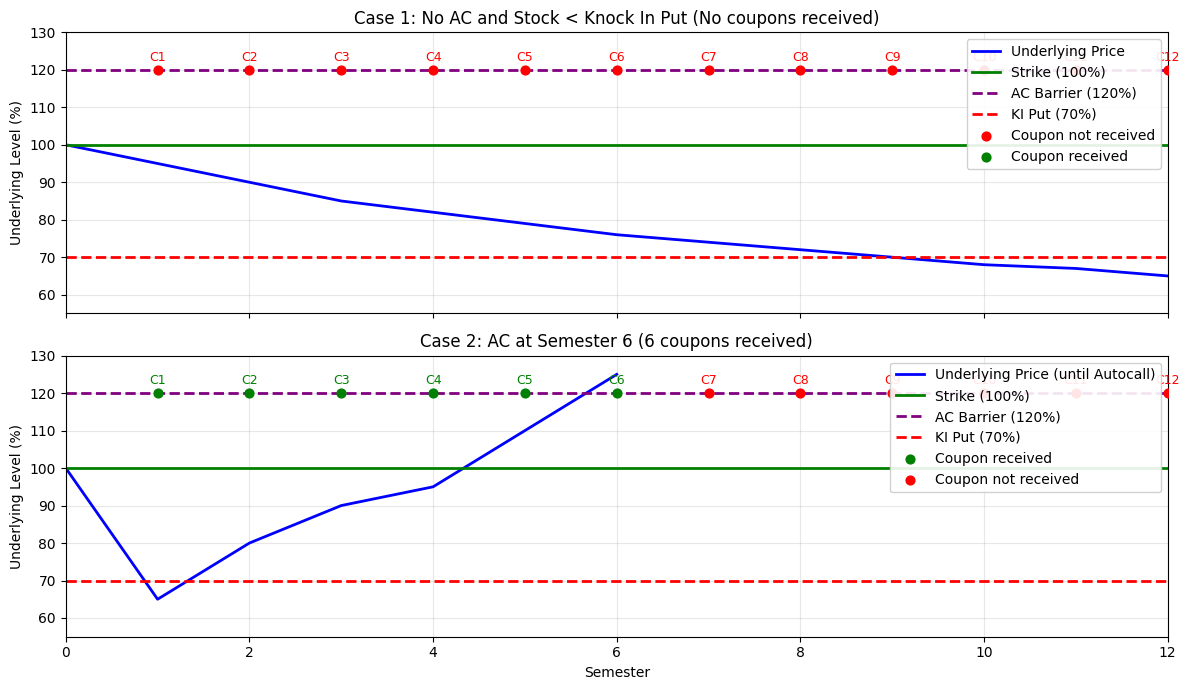

In [23]:
def plot_autocall_coupon_paths():
    # ----------------------------
    # PARAMETERS (in % of S0)
    # ----------------------------
    STRIKE = 100.0
    AC_BARRIER = 120.0
    KI_BARRIER = 70.0

    n_semesters = 12
    semesters = np.arange(0, n_semesters + 1)  # 0..12

    # Coupon observation points are at semesters 1..12
    obs_sem = np.arange(1, n_semesters + 1)
    obs_labels = [f"C{i}" for i in obs_sem]

    # ----------------------------
    # CASE 1: No Autocall, final < KI (no coupons received)
    # Example path: drifts down, ends below 70%
    # ----------------------------
    path_case1 = np.array([100, 95, 90, 85, 82, 79, 76, 74, 72, 70, 68, 67, 65], dtype=float)

    # ----------------------------
    # CASE 2: Autocall at Semester 6 (6 coupons received)
    # Example path: dips then rallies above AC at semester 6
    # Note: after autocall, we do NOT plot the path further (truncate)
    # ----------------------------
    path_case2_full = np.array([100, 65, 80, 90, 95, 110, 125, 120, 118, 121, 119, 122, 120], dtype=float)
    ac_semester = 6  # autocall occurs at semester 6
    path_case2 = path_case2_full[:ac_semester + 1]  # include semester 6 point
    semesters_case2 = semesters[:ac_semester + 1]

    # ----------------------------
    # PLOT SETUP
    # ----------------------------
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    plt.subplots_adjust(hspace=0.35)

    # Helper to draw horizontal levels
    def draw_levels(ax):
        ax.axhline(STRIKE, color='green', linewidth=2, label='Strike (100%)')
        ax.axhline(AC_BARRIER, color='purple', linestyle='--', linewidth=2, label='AC Barrier (120%)')
        ax.axhline(KI_BARRIER, color='red', linestyle='--', linewidth=2, label='KI Put (70%)')
        ax.set_ylim(55, 130)
        ax.set_ylabel('Underlying Level (%)')
        ax.grid(True, alpha=0.3)

    # ----------------------------
    # CASE 1 PLOT
    # ----------------------------
    ax1 = axes[0]
    ax1.set_title('Case 1: No AC and Stock < Knock In Put (No coupons received)')

    ax1.plot(semesters, path_case1, color='blue', linewidth=2, label='Underlying Price')
    draw_levels(ax1)

    # Coupon dots and labels (all NOT received)
    y_coupon_line = AC_BARRIER  # markers displayed on AC barrier line as in your image
    ax1.scatter(obs_sem, np.full_like(obs_sem, y_coupon_line), color='red', s=40, label='Coupon not received', zorder=5)

    for x, lab in zip(obs_sem, obs_labels):
        ax1.text(x, y_coupon_line + 1.5, lab, color='red', ha='center', va='bottom', fontsize=9)

    # Ensure legend order similar to screenshot
    handles, labels = ax1.get_legend_handles_labels()
    # Add a dummy for "Coupon received" so legend shows both
    dummy_received = ax1.scatter([], [], color='green', s=40, label='Coupon received')
    handles, labels = ax1.get_legend_handles_labels()
    ax1.legend(handles, labels, loc='upper right', framealpha=0.9)

    # ----------------------------
    # CASE 2 PLOT
    # ----------------------------
    ax2 = axes[1]
    ax2.set_title(f'Case 2: AC at Semester {ac_semester} ({ac_semester} coupons received)')

    ax2.plot(semesters_case2, path_case2, color='blue', linewidth=2, label='Underlying Price (until Autocall)')
    draw_levels(ax2)

    # Coupon received: semesters 1..ac_semester (green)
    received_sem = np.arange(1, ac_semester + 1)
    not_received_sem = np.arange(ac_semester + 1, n_semesters + 1)

    ax2.scatter(received_sem, np.full_like(received_sem, y_coupon_line), color='green', s=40, label='Coupon received', zorder=5)
    ax2.scatter(not_received_sem, np.full_like(not_received_sem, y_coupon_line), color='red', s=40, label='Coupon not received', zorder=5)

    # Labels C1..C12
    for x, lab in zip(obs_sem, obs_labels):
        col = 'green' if x <= ac_semester else 'red'
        ax2.text(x, y_coupon_line + 1.5, lab, color=col, ha='center', va='bottom', fontsize=9)

    ax2.set_xlabel('Semester')
    ax2.set_xlim(0, n_semesters)

    ax2.legend(loc='upper right', framealpha=0.9)

    plt.tight_layout()
    plt.show()

# Run
plot_autocall_coupon_paths()
